# 03_preprocessing

issue_report.pkl 기반 필터링 → Combo Group split → YOLO 포맷 변환.

**입력**: `eda/issue_report.pkl` (41,225행)  
**출력**: YOLO 학습 데이터 (images/labels × train/val), data.yaml, class_mapping.pkl, train/val.csv

**구성**

| Phase | Cell | |
|---|---|---|
| Setup & Load | 1~2 | 환경 / 데이터 로드 |
| 필터링 | 3~5 | 494건 제외 / dedup / class_idx |
| 이미지 검증 | 6~8 | 해상도 / 실존 / bbox 포맷 |
| Split | 9~10 | Combo Group + 검증 |
| YOLO 변환 | 11~14 | 디렉터리 / 라벨 / 이미지 / yaml |
| 검증 & 저장 | 15~19 | 전수 검증 / 시각화 / 리포트 |

## Cell 1 — Setup

경로 상수, 시드(42), 한글 폰트, 필수 파일 존재 확인.

In [27]:
# ============================================================
# Cell 1 — Setup
# ============================================================

import sys
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', message='.*Glyph.*missing from font.*')

sys.path.insert(0, str(Path().resolve()))   # eda/ 폴더 자체 → from utils.viz_helpers 작동
from utils.viz_helpers import setup_korean_font
setup_korean_font()

# 경로
# 노트북 위치 기반 동적 경로 (eda/ 안에서 실행 가정)
NOTEBOOK_DIR = Path().resolve()       # D:/pill_detection/eda
PROJECT_ROOT = NOTEBOOK_DIR.parent    # D:/pill_detection
DATA_ROOT    = PROJECT_ROOT / "data"
EDA_DIR      = PROJECT_ROOT / "eda"

ISSUE_REPORT_PATH = EDA_DIR / "issue_report.pkl"

# YOLO
YOLO_ROOT    = DATA_ROOT / "yolo"
YOLO_IMG_TR  = YOLO_ROOT / "images" / "train"
YOLO_IMG_VAL = YOLO_ROOT / "images" / "val"
YOLO_LBL_TR  = YOLO_ROOT / "labels" / "train"
YOLO_LBL_VAL = YOLO_ROOT / "labels" / "val"
DATA_YAML    = YOLO_ROOT / "data.yaml"

# COCO (Faster R-CNN용) 
COCO_ROOT  = DATA_ROOT / "coco"
TRAIN_COCO = COCO_ROOT / "train_coco.json"
VAL_COCO   = COCO_ROOT / "val_coco.json"

TRAIN_CSV       = EDA_DIR / "train.csv"
VAL_CSV         = EDA_DIR / "val.csv"
CLASS_MAP_PKL   = EDA_DIR / "class_mapping.pkl"
SPLIT_INFO_JSON = EDA_DIR / "split_info.json"

# 하이퍼파라미터
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# 필수 경로 검증
assert ISSUE_REPORT_PATH.exists(), f"issue_report.pkl 없음: {ISSUE_REPORT_PATH}"
assert DATA_ROOT.exists(), f"data 폴더 없음: {DATA_ROOT}"
assert EDA_DIR.exists(), f"eda 폴더 없음: {EDA_DIR}"

print("=" * 60)
print("Setup 완료")
print("=" * 60)
print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"ISSUE_REPORT : {ISSUE_REPORT_PATH.name} "
      f"({ISSUE_REPORT_PATH.stat().st_size / 1024 / 1024:.2f} MB)")
print(f"YOLO_ROOT    : {YOLO_ROOT}")
print(f"COCO_ROOT    : {COCO_ROOT}")
print(f"SEED         : {SEED}")
print(f"Python {sys.version.split()[0]} / numpy {np.__version__} / pandas {pd.__version__}")

✅ 한글 폰트 설정: Malgun Gothic
Setup 완료
PROJECT_ROOT : D:\pill_detection
ISSUE_REPORT : issue_report.pkl (47.10 MB)
YOLO_ROOT    : D:\pill_detection\data\yolo
COCO_ROOT    : D:\pill_detection\data\coco
SEED         : 42
Python 3.11.9 / numpy 1.26.4 / pandas 2.2.3


## Cell 2 — Load & Sanity Check

issue_report.pkl 로드 후 03에서 필요한 컬럼 전수 존재 확인.

In [28]:
# ============================================================
# Cell 2 — Load & Sanity Check
# ============================================================

df_report = pd.read_pickle(ISSUE_REPORT_PATH)

print(f"shape       : {df_report.shape}")
print(f"memory      : {df_report.memory_usage(deep=True).sum() / 1024 / 1024:.2f} MB")
print()

# 03에서 반드시 필요한 컬럼
REQUIRED_COLS = [
    # 식별
    'image_file',           # 이미지 파일명 (groupby 키)
    'combo',                # Combo Group split 키
    'source',               # Kaggle / AI Hub 구분

    # 학습 타겟 (3중 키)
    'img_dl_name',          # 학습 클래스명
    'img_dl_mapping_code',  # 3중 키 검증용
    'img_drug_N',           # 3중 키 검증용

    # 필터링 플래그
    'exclude_from_train',   # True면 제외

    # bbox (YOLO 변환 입력)
    'bbox',                 # 원본 bbox (포맷은 Cell 8에서 확증)

    # 이미지 메타
    'image_path',           # 실제 파일 경로 (YOLO 이미지 배치용)
]

missing = [c for c in REQUIRED_COLS if c not in df_report.columns]
present = [c for c in REQUIRED_COLS if c in df_report.columns]

print(f"필수 컬럼 {len(REQUIRED_COLS)}개 중 present {len(present)} / missing {len(missing)}")
if missing:
    print(f"❌ MISSING: {missing}")
else:
    print("✅ 전부 존재")

print()
print("=" * 60)
print("dtype & 결측률 (필수 컬럼)")
print("=" * 60)
for c in present:
    na = df_report[c].isna().sum()
    pct = na / len(df_report) * 100
    print(f"  {c:25s} {str(df_report[c].dtype):15s} NA={na:>6,} ({pct:5.2f}%)")

print()
print("=" * 60)
print("exclude_from_train 분포")
print("=" * 60)
print(df_report['exclude_from_train'].value_counts(dropna=False))

shape       : (41225, 85)
memory      : 181.31 MB

필수 컬럼 9개 중 present 8 / missing 1
❌ MISSING: ['bbox']

dtype & 결측률 (필수 컬럼)
  image_file                object          NA=     1 ( 0.00%)
  combo                     object          NA=     0 ( 0.00%)
  source                    object          NA=     0 ( 0.00%)
  img_dl_name               object          NA=    49 ( 0.12%)
  img_dl_mapping_code       object          NA=    49 ( 0.12%)
  img_drug_N                object          NA=    49 ( 0.12%)
  exclude_from_train        bool            NA=     0 ( 0.00%)
  image_path                object          NA=   121 ( 0.29%)

exclude_from_train 분포
exclude_from_train
False    40731
True       494
Name: count, dtype: int64


## Cell 2.5 — 컬럼 실체 확인

bbox 관련 컬럼 실제 이름 파악 + 결측 위치가 exclude=True에 국한되는지 확증.

In [29]:
# ============================================================
# Cell 2.5 — 컬럼 실체 확인 (bbox + 결측 위치)
# ============================================================

# (1) bbox 관련 컬럼 탐색
bbox_candidates = [c for c in df_report.columns 
                   if 'bbox' in c.lower() or 'box' in c.lower()]
coord_candidates = [c for c in df_report.columns 
                    if c.lower() in ['x', 'y', 'w', 'h', 'x1', 'y1', 'x2', 'y2',
                                     'cx', 'cy', 'width', 'height']]

print("=" * 60)
print("bbox 관련 컬럼")
print("=" * 60)
for c in bbox_candidates + coord_candidates:
    sample = df_report[c].dropna().iloc[0] if df_report[c].notna().any() else "ALL NA"
    print(f"  {c:25s} dtype={str(df_report[c].dtype):12s} "
          f"NA={df_report[c].isna().sum():>6,}  sample={sample}")

# (2) 결측이 exclude=True에 국한되는지 확증
print()
print("=" * 60)
print("정상 레코드(exclude=False, 40,731건) 내 결측")
print("=" * 60)
df_ok = df_report[~df_report['exclude_from_train']]
check_cols = ['image_file', 'img_dl_name', 'img_dl_mapping_code',
              'img_drug_N', 'image_path']
for c in check_cols:
    na = df_ok[c].isna().sum()
    flag = "✅" if na == 0 else "❌"
    print(f"  {flag} {c:25s} NA={na}")

# (3) 전체 컬럼 목록 (85개)
print()
print("=" * 60)
print(f"전체 컬럼 {len(df_report.columns)}개")
print("=" * 60)
for i, c in enumerate(df_report.columns):
    print(f"  [{i:2d}] {c}")

bbox 관련 컬럼
  bbox_raw                  dtype=object       NA=    49  sample=[644, 845, 189, 190]
  bbox_valid                dtype=object       NA=    49  sample=True
  bbox_x                    dtype=float64      NA=   204  sample=644.0
  bbox_y                    dtype=float64      NA=   204  sample=845.0
  bbox_w                    dtype=float64      NA=   204  sample=189.0
  bbox_h                    dtype=float64      NA=   204  sample=190.0

정상 레코드(exclude=False, 40,731건) 내 결측
  ✅ image_file                NA=0
  ✅ img_dl_name               NA=0
  ✅ img_dl_mapping_code       NA=0
  ✅ img_drug_N                NA=0
  ✅ image_path                NA=0

전체 컬럼 85개
  [ 0] source
  [ 1] source_json
  [ 2] combo
  [ 3] kcode_folder
  [ 4] image_file
  [ 5] image_path
  [ 6] image_exists
  [ 7] angle
  [ 8] ann_id
  [ 9] ann_image_id
  [10] category_id_raw
  [11] bbox_raw
  [12] bbox_valid
  [13] bbox_x
  [14] bbox_y
  [15] bbox_w
  [16] bbox_h
  [17] area_raw
  [18] iscrowd
  [19] ignore

## Cell 2.6 — bbox 결측 & dedup 플래그 확인

정상 레코드 내 bbox NA 여부, dedup_keep과 exclude_from_train 관계.

In [30]:
# ============================================================
# Cell 2.6 — bbox 결측 & dedup 플래그 확인
# ============================================================

df_ok = df_report[~df_report['exclude_from_train']]

# (1) 정상 레코드 내 bbox 결측
print("=" * 60)
print("정상 40,731건 내 bbox_x/y/w/h 결측")
print("=" * 60)
for c in ['bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']:
    na = df_ok[c].isna().sum()
    flag = "✅" if na == 0 else "❌"
    print(f"  {flag} {c:10s} NA={na}")

# (2) dedup_keep 분포 (전체 & exclude별)
print()
print("=" * 60)
print("dedup_keep × exclude_from_train 교차표")
print("=" * 60)
print(pd.crosstab(df_report['dedup_keep'],
                  df_report['exclude_from_train'],
                  margins=True, dropna=False))

# (3) is_duplicate_key 분포
print()
print("=" * 60)
print("is_duplicate_key × exclude_from_train 교차표")
print("=" * 60)
print(pd.crosstab(df_report['is_duplicate_key'],
                  df_report['exclude_from_train'],
                  margins=True, dropna=False))

# (4) 이슈 플래그별 정상 레코드 포함 여부
print()
print("=" * 60)
print("이슈 플래그 × exclude_from_train (True만 출력)")
print("=" * 60)
for col in ['issue_A', 'issue_B_extreme', 'issue_C_iou1', 
            'issue_L', 'issue_M', 'issue_N']:
    issue_true = df_report[df_report[col] == True]
    if len(issue_true) == 0:
        continue
    excluded = issue_true['exclude_from_train'].sum()
    kept = len(issue_true) - excluded
    print(f"  {col:20s} 총 {len(issue_true):>5,}건  "
          f"exclude={excluded:>5,} / keep={kept:>5,}")

정상 40,731건 내 bbox_x/y/w/h 결측
  ✅ bbox_x     NA=0
  ✅ bbox_y     NA=0
  ✅ bbox_w     NA=0
  ✅ bbox_h     NA=0

dedup_keep × exclude_from_train 교차표
exclude_from_train  False  True    All
dedup_keep                            
False                   0    71     71
True                40731   423  41154
All                 40731   494  41225

is_duplicate_key × exclude_from_train 교차표
exclude_from_train  False  True    All
is_duplicate_key                      
False               40661   422  41083
True                   70    72    142
All                 40731   494  41225

이슈 플래그 × exclude_from_train (True만 출력)
  issue_A              총    58건  exclude=   58 / keep=    0
  issue_B_extreme      총    40건  exclude=   40 / keep=    0
  issue_C_iou1         총   142건  exclude=   72 / keep=   70
  issue_L              총     1건  exclude=    1 / keep=    0
  issue_M              총     1건  exclude=    0 / keep=    1
  issue_N              총    90건  exclude=    1 / keep=   89


## Cell 3 — 필터링 (494건 제외)

exclude_from_train 플래그로 40,731건 추출. 제외 사유별 breakdown 확증.

In [31]:
# ============================================================
# Cell 3 — 필터링
# ============================================================

print("=" * 60)
print("제외 494건 breakdown")
print("=" * 60)

excluded = df_report[df_report['exclude_from_train']]

# parse_error는 사유 문자열 → notna()로 카운트
reasons = {
    'parse_error'      : excluded['parse_error'].notna().sum(),
    'issue_A (경계)'    : excluded['issue_A'].sum(),
    'issue_B_extreme'  : excluded['issue_B_extreme'].sum(),
    'issue_L (iscrowd)': excluded['issue_L'].sum(),
    'issue_C dedup'    : (~excluded['dedup_keep']).sum(),
}
for reason, cnt in reasons.items():
    print(f"  {reason:25s} {cnt:>5,}건")

# parse_error 세부 사유
print()
print("  parse_error 세부:")
print(excluded['parse_error'].value_counts(dropna=False).to_string())

# 필터링
df_clean = df_report[~df_report['exclude_from_train']].copy()

# 불변 조건
assert len(df_clean) == 40731, f"40,731 아님: {len(df_clean)}"
assert df_clean['image_file'].isna().sum() == 0
assert df_clean[['bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].isna().sum().sum() == 0
assert df_clean['img_dl_name'].isna().sum() == 0

print()
print("=" * 60)
print("df_clean 요약")
print("=" * 60)
print(f"  레코드    : {len(df_clean):,}")
print(f"  고유 이미지: {df_clean['image_file'].nunique():,}")
print(f"  고유 combo : {df_clean['combo'].nunique():,}")
print(f"  고유 클래스: {df_clean['img_dl_name'].nunique()}")
print(f"  source별   : {df_clean['source'].value_counts().to_dict()}")

제외 494건 breakdown
  parse_error                 324건
  issue_A (경계)                 58건
  issue_B_extreme              40건
  issue_L (iscrowd)             1건
  issue_C dedup                71건

  parse_error 세부:
parse_error
None                                                              170
bbox_format_error                                                 155
orphan_label                                                      120
orphan_image                                                       48
json_load_fail: Expecting value: line 59 column 12 (char 1571)      1

df_clean 요약
  레코드    : 40,731
  고유 이미지: 10,697
  고유 combo : 3,604
  고유 클래스: 118
  source별   : {'aihub_ts1_tl1': 5969, 'aihub_ts5_tl5': 5923, 'aihub_ts6_tl6': 5921, 'aihub_ts3_tl3': 5668, 'aihub_ts8_tl8': 5587, 'aihub_ts7_tl7': 5500, 'aihub_ts4_tl4': 5404, 'kaggle_train': 759}


## Cell 4 — class_idx 재매핑

3중 키 (img_dl_name / img_dl_mapping_code / img_drug_N) 무결성 assert 후
sorted(img_dl_name.unique())에 0~117 인덱스 부여. 양방향 매핑 저장.

In [32]:
# ============================================================
# Cell 4 — class_idx 재매핑
# ============================================================

import pickle

# (1) 3중 키 무결성 assert (Cell 16C 결과 재확증)
triple = df_clean[['img_dl_name', 'img_dl_mapping_code', 'img_drug_N']].drop_duplicates()
n_name = df_clean['img_dl_name'].nunique()
n_code = df_clean['img_dl_mapping_code'].nunique()
n_drug = df_clean['img_drug_N'].nunique()

print("=" * 60)
print("3중 키 무결성")
print("=" * 60)
print(f"  img_dl_name          unique = {n_name}")
print(f"  img_dl_mapping_code  unique = {n_code}")
print(f"  img_drug_N           unique = {n_drug}")
print(f"  3중 조합             unique = {len(triple)}")

assert n_name == 118, f"img_dl_name != 118: {n_name}"
assert n_code == 118, f"mapping_code != 118: {n_code}"
assert n_drug == 118, f"drug_N != 118: {n_drug}"
assert len(triple) == 118, f"3중 조합 != 118: {len(triple)}"
print("  ✅ 118:118:118:118 완전 일치")

# (2) class_idx 재매핑
class_names = sorted(df_clean['img_dl_name'].unique())
name_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_name = {idx: name for name, idx in name_to_idx.items()}

df_clean['class_idx'] = df_clean['img_dl_name'].map(name_to_idx)

# (3) 매핑 결과 검증
assert df_clean['class_idx'].isna().sum() == 0, "매핑 누락 존재"
assert df_clean['class_idx'].min() == 0
assert df_clean['class_idx'].max() == 117
assert df_clean['class_idx'].nunique() == 118

# 역매핑 round-trip
sample = df_clean.sample(100, random_state=42)
for _, row in sample.iterrows():
    assert idx_to_name[row['class_idx']] == row['img_dl_name']
print()
print("=" * 60)
print("class_idx 매핑")
print("=" * 60)
print(f"  범위          : [{df_clean['class_idx'].min()}, {df_clean['class_idx'].max()}]")
print(f"  unique        : {df_clean['class_idx'].nunique()}")
print(f"  역매핑 round-trip: ✅ 100건 전부 일치")

# (4) 3중 키 → class_idx 매핑 테이블 생성 (보조 자료)
triple_map = df_clean[['class_idx', 'img_dl_name', 'img_dl_mapping_code', 'img_drug_N']]\
             .drop_duplicates().sort_values('class_idx').reset_index(drop=True)
assert len(triple_map) == 118

# (5) 저장
class_mapping = {
    'class_names'     : class_names,          # list, idx 순서대로
    'name_to_idx'     : name_to_idx,          # name → idx
    'idx_to_name'     : idx_to_name,          # idx → name
    'triple_map'      : triple_map,           # idx/name/code/drug_N 표
    'nc'              : 118,
}
with open(CLASS_MAP_PKL, 'wb') as f:
    pickle.dump(class_mapping, f)

print(f"\n✅ 저장: {CLASS_MAP_PKL.name} ({CLASS_MAP_PKL.stat().st_size} bytes)")

# (6) 상위/하위 3개 클래스 샘플 출력
print()
print("샘플 (idx 0~2 / 115~117):")
for idx in [0, 1, 2, 115, 116, 117]:
    name = idx_to_name[idx]
    cnt = (df_clean['class_idx'] == idx).sum()
    print(f"  [{idx:3d}] {name[:40]:40s} — {cnt:,}건")

3중 키 무결성
  img_dl_name          unique = 118
  img_dl_mapping_code  unique = 118
  img_drug_N           unique = 118
  3중 조합             unique = 118
  ✅ 118:118:118:118 완전 일치

class_idx 매핑
  범위          : [0, 117]
  unique        : 118
  역매핑 round-trip: ✅ 100건 전부 일치

✅ 저장: class_mapping.pkl (9198 bytes)

샘플 (idx 0~2 / 115~117):
  [  0] 가바토파정 100mg                              — 924건
  [  1] 게보린정 300mg/PTP                           — 449건
  [  2] 글리아타민연질캡슐                                — 142건
  [115] 플라빅스정 75mg                               — 593건
  [116] 플리바스정 50mg                               — 84건
  [117] 한미탐스캡슐 0.2mg                             — 287건


## Cell 5 — 이미지 해상도 검증

img_width / img_height 단일성 확증. YOLO 변환은 이미지별 normalize 필요하므로
여러 해상도 혼재 시 per-image 처리 로직 필요.

In [33]:
# ============================================================
# Cell 5 — 이미지 해상도 검증
# ============================================================

# (1) source별 해상도 분포
print("=" * 60)
print("source × 해상도 분포")
print("=" * 60)
wh = df_clean.groupby(['source', 'img_width', 'img_height']).size()\
             .reset_index(name='count')
print(wh.to_string(index=False))

# (2) 고유 해상도
unique_wh = df_clean[['img_width', 'img_height']].drop_duplicates()
print()
print(f"고유 해상도 수: {len(unique_wh)}")
print(unique_wh.to_string(index=False))

# (3) 결측 확인
print()
na_w = df_clean['img_width'].isna().sum()
na_h = df_clean['img_height'].isna().sum()
print(f"img_width  NA: {na_w}")
print(f"img_height NA: {na_h}")

# (4) 결정
print()
print("=" * 60)
print("결론")
print("=" * 60)
if len(unique_wh) == 1:
    w = int(unique_wh.iloc[0]['img_width'])
    h = int(unique_wh.iloc[0]['img_height'])
    print(f"✅ 단일 해상도: {w} × {h}")
    print(f"  → YOLO 변환 시 전역 상수 사용 가능")
else:
    print(f"⚠️  {len(unique_wh)}종 해상도 혼재")
    print(f"  → Cell 12(YOLO 라벨 변환)에서 행 단위 img_width/img_height 사용")

source × 해상도 분포
       source  img_width  img_height  count
aihub_ts1_tl1      976.0      1280.0   5969
aihub_ts3_tl3      976.0      1280.0   5668
aihub_ts4_tl4      976.0      1280.0   5404
aihub_ts5_tl5      976.0      1280.0   5923
aihub_ts6_tl6      976.0      1280.0   5921
aihub_ts7_tl7      976.0      1280.0   5500
aihub_ts8_tl8      976.0      1280.0   5587
 kaggle_train      976.0      1280.0    759

고유 해상도 수: 1
 img_width  img_height
     976.0      1280.0

img_width  NA: 0
img_height NA: 0

결론
✅ 단일 해상도: 976 × 1280
  → YOLO 변환 시 전역 상수 사용 가능


## Cell 6 — 이미지 파일 실존 검증

image_path 기반 전수 os.path.exists. 누락 시 원인 규명.
10,697 고유 이미지 단위로만 체크(중복 I/O 방지).

In [34]:
# ============================================================
# Cell 6 — 이미지 파일 실존 검증
# ============================================================

from tqdm import tqdm

# (1) 고유 image_path 추출 (중복 I/O 방지)
unique_paths = df_clean['image_path'].unique()
print(f"고유 image_path : {len(unique_paths):,}")
print(f"고유 image_file : {df_clean['image_file'].nunique():,}")
print()

# (2) 전수 존재 확인
print("전수 os.path.exists 검증...")
missing_paths = []
for p in tqdm(unique_paths):
    if not os.path.exists(p):
        missing_paths.append(p)

# (3) 결과
print()
print("=" * 60)
print("결과")
print("=" * 60)
total = len(unique_paths)
ok = total - len(missing_paths)
print(f"  존재    : {ok:,} / {total:,} ({ok/total*100:.2f}%)")
print(f"  누락    : {len(missing_paths):,}")

if missing_paths:
    print()
    print("누락 샘플 (최대 10개):")
    for p in missing_paths[:10]:
        print(f"  {p}")
    
    # 누락 원인 분석 — 어떤 source에 속하는지
    missing_df = df_clean[df_clean['image_path'].isin(missing_paths)]
    print()
    print("누락 path의 source 분포:")
    print(missing_df['source'].value_counts().to_string())
else:
    print()
    print("✅ 전수 존재 확증")

# (4) 확장자 통계
print()
print("=" * 60)
print("확장자 분포")
print("=" * 60)
exts = pd.Series([Path(p).suffix.lower() for p in unique_paths])
print(exts.value_counts().to_string())

고유 image_path : 10,697
고유 image_file : 10,697

전수 os.path.exists 검증...


100%|██████████| 10697/10697 [00:01<00:00, 8931.55it/s]



결과
  존재    : 10,697 / 10,697 (100.00%)
  누락    : 0

✅ 전수 존재 확증

확장자 분포
.png    10697


## Cell 7 — bbox 좌표 유효성 검증

COCO 포맷 [x, y, w, h] 전제 검증.
범위 체크: 0 ≤ x, 0 ≤ y, x+w ≤ 976, y+h ≤ 1280.
경계 위반은 issue_A로 이미 exclude된 상태 → 생존 40,731건 전부 safe 확증.

In [35]:
# ============================================================
# Cell 7 — bbox 좌표 유효성 검증
# ============================================================

IMG_W, IMG_H = 976, 1280

# (1) bbox_x/y/w/h 기본 통계
print("=" * 60)
print("bbox 기본 통계")
print("=" * 60)
print(df_clean[['bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].describe().round(2))

# (2) 불변 조건 검증
print()
print("=" * 60)
print("불변 조건 검증")
print("=" * 60)

violations = {
    'x < 0'        : (df_clean['bbox_x'] < 0).sum(),
    'y < 0'        : (df_clean['bbox_y'] < 0).sum(),
    'w <= 0'       : (df_clean['bbox_w'] <= 0).sum(),
    'h <= 0'       : (df_clean['bbox_h'] <= 0).sum(),
    'x + w > 976'  : (df_clean['bbox_x'] + df_clean['bbox_w'] > IMG_W).sum(),
    'y + h > 1280' : (df_clean['bbox_y'] + df_clean['bbox_h'] > IMG_H).sum(),
}

for rule, cnt in violations.items():
    flag = "✅" if cnt == 0 else "❌"
    print(f"  {flag} {rule:20s} 위반: {cnt:,}건")

total_violations = sum(violations.values())

# (3) 위반 있으면 상세 조회
if total_violations > 0:
    print()
    print("=" * 60)
    print("위반 샘플 (최대 10개)")
    print("=" * 60)
    mask = (
        (df_clean['bbox_x'] < 0) |
        (df_clean['bbox_y'] < 0) |
        (df_clean['bbox_w'] <= 0) |
        (df_clean['bbox_h'] <= 0) |
        (df_clean['bbox_x'] + df_clean['bbox_w'] > IMG_W) |
        (df_clean['bbox_y'] + df_clean['bbox_h'] > IMG_H)
    )
    print(df_clean[mask][['source', 'image_file', 
                         'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']].head(10).to_string())
else:
    print()
    print("✅ 40,731건 전부 COCO 규격 내 (0 ≤ 좌표, x+w ≤ 976, y+h ≤ 1280)")
    print("   → YOLO normalize 시 clip 불필요")

# (4) 극단값 분포 (w, h 최소/최대)
print()
print("=" * 60)
print("bbox 크기 극단값")
print("=" * 60)
print(f"  최소 width : {df_clean['bbox_w'].min():.1f} px")
print(f"  최소 height: {df_clean['bbox_h'].min():.1f} px")
print(f"  최대 width : {df_clean['bbox_w'].max():.1f} px")
print(f"  최대 height: {df_clean['bbox_h'].max():.1f} px")
print(f"  픽셀 면적 1,000 미만: {(df_clean['bbox_w'] * df_clean['bbox_h'] < 1000).sum():,}건")

bbox 기본 통계
         bbox_x    bbox_y    bbox_w    bbox_h
count  40731.00  40731.00  40731.00  40731.00
mean     348.80    466.76    267.65    319.82
std      239.52    304.06     77.14    120.55
min        0.00      0.00     63.00     75.00
25%      113.00    175.00    210.00    213.00
50%      362.00    544.00    247.00    285.00
75%      595.00    774.00    313.00    437.00
max      725.00    983.00    828.00    980.00

불변 조건 검증
  ✅ x < 0                위반: 0건
  ✅ y < 0                위반: 0건
  ✅ w <= 0               위반: 0건
  ✅ h <= 0               위반: 0건
  ✅ x + w > 976          위반: 0건
  ✅ y + h > 1280         위반: 0건

✅ 40,731건 전부 COCO 규격 내 (0 ≤ 좌표, x+w ≤ 976, y+h ≤ 1280)
   → YOLO normalize 시 clip 불필요

bbox 크기 극단값
  최소 width : 63.0 px
  최소 height: 75.0 px
  최대 width : 828.0 px
  최대 height: 980.0 px
  픽셀 면적 1,000 미만: 0건


## Cell 8 — Combo Group Split

sklearn GroupShuffleSplit. groups=combo, test_size=0.2, seed=42.
이미지·combo overlap 0, class 118/118 유지가 목표 (Cell 13 시뮬레이션 결과).

In [36]:
# ============================================================
# Cell 8 — Combo Group Split
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# 하이퍼파라미터 (이 셀 로컬)
VAL_RATIO = 0.2

print("=" * 60)
print("Split 실행")
print("=" * 60)
print(f"  전략       : GroupShuffleSplit by combo")
print(f"  val_ratio  : {VAL_RATIO}")
print(f"  seed       : {SEED}")
print(f"  전체       : {len(df_clean):,}건 / {df_clean['combo'].nunique():,} combo")

gss = GroupShuffleSplit(n_splits=1, test_size=VAL_RATIO, random_state=SEED)
train_idx, val_idx = next(gss.split(df_clean, groups=df_clean['combo']))

train_df = df_clean.iloc[train_idx].copy().reset_index(drop=True)
val_df   = df_clean.iloc[val_idx].copy().reset_index(drop=True)

# (2) 기본 통계
print()
print("=" * 60)
print("Split 결과")
print("=" * 60)

def split_stats(name, df):
    print(f"\n[{name}]")
    print(f"  레코드    : {len(df):,}")
    print(f"  이미지    : {df['image_file'].nunique():,}")
    print(f"  combo     : {df['combo'].nunique():,}")
    print(f"  클래스    : {df['img_dl_name'].nunique()}")
    print(f"  source    : {df['source'].value_counts().to_dict()}")

split_stats("TRAIN", train_df)
split_stats("VAL",   val_df)

# (3) 비율 확인
print()
print("=" * 60)
print("비율 검증")
print("=" * 60)
ratio = len(val_df) / (len(train_df) + len(val_df))
print(f"  실제 val 비율: {ratio:.4f} (목표 {VAL_RATIO})")
assert 0.15 < ratio < 0.25, f"비율 이상: {ratio}"
print(f"  ✅ 허용 범위 [0.15, 0.25]")

Split 실행
  전략       : GroupShuffleSplit by combo
  val_ratio  : 0.2
  seed       : 42
  전체       : 40,731건 / 3,604 combo

Split 결과

[TRAIN]
  레코드    : 32,601
  이미지    : 8,558
  combo     : 2,883
  클래스    : 118
  source    : {'aihub_ts5_tl5': 4825, 'aihub_ts6_tl6': 4808, 'aihub_ts3_tl3': 4624, 'aihub_ts1_tl1': 4508, 'aihub_ts8_tl8': 4507, 'aihub_ts7_tl7': 4411, 'aihub_ts4_tl4': 4364, 'kaggle_train': 554}

[VAL]
  레코드    : 8,130
  이미지    : 2,139
  combo     : 721
  클래스    : 118
  source    : {'aihub_ts1_tl1': 1461, 'aihub_ts6_tl6': 1113, 'aihub_ts5_tl5': 1098, 'aihub_ts7_tl7': 1089, 'aihub_ts8_tl8': 1080, 'aihub_ts3_tl3': 1044, 'aihub_ts4_tl4': 1040, 'kaggle_train': 205}

비율 검증
  실제 val 비율: 0.1996 (목표 0.2)
  ✅ 허용 범위 [0.15, 0.25]


## Cell 9 — Split 검증

불변 조건 assert:
- 이미지 overlap = 0
- combo overlap = 0
- train/val 클래스 모두 118
- 클래스별 불균형 점검 (val에 극소수인 클래스 존재 여부)

In [37]:
# ============================================================
# Cell 9 — Split 검증
# ============================================================

# (1) 이미지/combo overlap 검증
train_imgs = set(train_df['image_file'])
val_imgs   = set(val_df['image_file'])
train_combos = set(train_df['combo'])
val_combos   = set(val_df['combo'])

img_overlap   = train_imgs & val_imgs
combo_overlap = train_combos & val_combos

print("=" * 60)
print("Overlap 검증")
print("=" * 60)
print(f"  이미지 overlap : {len(img_overlap):,}")
print(f"  combo overlap  : {len(combo_overlap):,}")

assert len(img_overlap) == 0, f"이미지 overlap {len(img_overlap)}"
assert len(combo_overlap) == 0, f"combo overlap {len(combo_overlap)}"
print("  ✅ overlap 0 확증")

# (2) 클래스 커버리지
train_classes = set(train_df['class_idx'])
val_classes   = set(val_df['class_idx'])
all_classes   = set(range(118))

print()
print("=" * 60)
print("클래스 커버리지")
print("=" * 60)
print(f"  train 클래스 : {len(train_classes)}")
print(f"  val   클래스 : {len(val_classes)}")
print(f"  unseen in val: {len(all_classes - val_classes)}")
print(f"  unseen in train: {len(all_classes - train_classes)}")

assert train_classes == all_classes, "train에 누락된 클래스"
assert val_classes == all_classes, "val에 누락된 클래스"
print("  ✅ train/val 모두 118종 전부 커버")

# (3) 클래스별 train/val 불균형 점검
cls_stats = pd.DataFrame({
    'train': train_df['class_idx'].value_counts(),
    'val'  : val_df['class_idx'].value_counts(),
}).fillna(0).astype(int)
cls_stats['total']     = cls_stats['train'] + cls_stats['val']
cls_stats['val_ratio'] = cls_stats['val'] / cls_stats['total']
cls_stats['name']      = cls_stats.index.map(idx_to_name)
cls_stats = cls_stats.sort_values('total')

print()
print("=" * 60)
print("클래스별 train/val 분포 (하위 10 — 희귀 클래스)")
print("=" * 60)
print(cls_stats[['name', 'train', 'val', 'total', 'val_ratio']].head(10).to_string())

# (4) val 건수가 5 미만인 클래스 경고
low_val = cls_stats[cls_stats['val'] < 5]
print()
if len(low_val) > 0:
    print(f"⚠️  val 건수 < 5인 클래스 {len(low_val)}개:")
    print(low_val[['name', 'train', 'val']].to_string())
    print("   → 해당 클래스는 val 성능 변동 클 수 있음 (baseline에서 주의)")
else:
    print("✅ 모든 클래스가 val에 5건 이상 존재")

# (5) val_ratio 극단 클래스
print()
print("=" * 60)
print("val_ratio 극단 클래스 (0.05 미만 또는 0.5 초과)")
print("=" * 60)
extreme = cls_stats[(cls_stats['val_ratio'] < 0.05) | (cls_stats['val_ratio'] > 0.5)]
if len(extreme) > 0:
    print(extreme[['name', 'train', 'val', 'val_ratio']].to_string())
else:
    print("✅ 모든 클래스 val_ratio ∈ [0.05, 0.5]")

Overlap 검증
  이미지 overlap : 0
  combo overlap  : 0
  ✅ overlap 0 확증

클래스 커버리지
  train 클래스 : 118
  val   클래스 : 118
  unseen in val: 0
  unseen in train: 0
  ✅ train/val 모두 118종 전부 커버

클래스별 train/val 분포 (하위 10 — 희귀 클래스)
                         name  train  val  total  val_ratio
class_idx                                                  
4          기넥신에프정(은행엽엑스)(수출용)     30   15     45   0.333333
41                 베시케어정 10mg     59   21     80   0.262500
111                 트루패스정 4mg     67   15     82   0.182927
88               자트랄엑스엘정 10mg     72   12     84   0.142857
106               토비애즈서방정 4mg     60   24     84   0.285714
116                플리바스정 50mg     63   21     84   0.250000
82           인사돌플러스정 35mg/PTP     63   27     90   0.300000
73           엔트레스토필름코팅정 200mg     74   32    106   0.301887
60            아질렉트정(라사길린메실산염)    116   20    136   0.147059
2                   글리아타민연질캡슐    124   18    142   0.126761

✅ 모든 클래스가 val에 5건 이상 존재

val_ratio 극단 클래스 (0.05 미만 또는 0.5 초과)


## Cell 10 — 디렉터리 구조 생성

data/yolo/{images,labels}/{train,val} + data/coco/.

In [38]:
# ============================================================
# Cell 10 — 디렉터리 구조 생성 (YOLO + COCO)
# ============================================================

import shutil

print("=" * 60)
print("기존 디렉터리 상태")
print("=" * 60)

# YOLO
if YOLO_ROOT.exists():
    n_tr_img  = len(list(YOLO_IMG_TR.glob("*.png"))) if YOLO_IMG_TR.exists() else 0
    n_val_img = len(list(YOLO_IMG_VAL.glob("*.png"))) if YOLO_IMG_VAL.exists() else 0
    n_tr_lbl  = len(list(YOLO_LBL_TR.glob("*.txt"))) if YOLO_LBL_TR.exists() else 0
    n_val_lbl = len(list(YOLO_LBL_VAL.glob("*.txt"))) if YOLO_LBL_VAL.exists() else 0
    print(f"  {YOLO_ROOT} 존재")
    print(f"    images/train : {n_tr_img:,} png")
    print(f"    images/val   : {n_val_img:,} png")
    print(f"    labels/train : {n_tr_lbl:,} txt")
    print(f"    labels/val   : {n_val_lbl:,} txt")
else:
    print(f"  {YOLO_ROOT} 없음 (신규)")

# COCO
if COCO_ROOT.exists():
    n_coco = len(list(COCO_ROOT.glob("*.json")))
    print(f"  {COCO_ROOT} 존재 ({n_coco} json)")
else:
    print(f"  {COCO_ROOT} 없음 (신규)")

# 생성
for d in [YOLO_IMG_TR, YOLO_IMG_VAL, YOLO_LBL_TR, YOLO_LBL_VAL, COCO_ROOT]:
    d.mkdir(parents=True, exist_ok=True)

print()
print("=" * 60)
print("생성 완료")
print("=" * 60)
for d in [YOLO_ROOT, YOLO_IMG_TR, YOLO_IMG_VAL, YOLO_LBL_TR, YOLO_LBL_VAL, COCO_ROOT]:
    status = "✅" if d.exists() else "❌"
    print(f"  {status} {d}")

기존 디렉터리 상태
  D:\pill_detection\data\yolo 존재
    images/train : 8,558 png
    images/val   : 2,139 png
    labels/train : 8,558 txt
    labels/val   : 2,139 txt
  D:\pill_detection\data\coco 존재 (2 json)

생성 완료
  ✅ D:\pill_detection\data\yolo
  ✅ D:\pill_detection\data\yolo\images\train
  ✅ D:\pill_detection\data\yolo\images\val
  ✅ D:\pill_detection\data\yolo\labels\train
  ✅ D:\pill_detection\data\yolo\labels\val
  ✅ D:\pill_detection\data\coco


## Cell 11 — YOLO 라벨 파일 생성

COCO [x,y,w,h] → YOLO normalized (cx,cy,w,h).
이미지 단위 groupby, 한 이미지당 .txt 파일 1개.
출력 좌표 [0,1] assert.

In [39]:
# ============================================================
# Cell 11 — YOLO 라벨 파일 생성
# ============================================================

from tqdm import tqdm

IMG_W, IMG_H = 976, 1280

def write_yolo_labels(df_split, out_dir, split_name):
    """
    df_split: train_df 또는 val_df
    out_dir : YOLO_LBL_TR 또는 YOLO_LBL_VAL
    """
    # 이미지 단위 groupby
    grouped = df_split.groupby('image_file')
    
    n_files   = 0
    n_anns    = 0
    coord_min, coord_max = 1.0, 0.0  # 전역 범위 추적
    
    for image_file, group in tqdm(grouped, desc=f"{split_name} labels"):
        # 라벨 파일명: image_file의 확장자만 .txt로
        label_name = Path(image_file).stem + ".txt"
        label_path = out_dir / label_name
        
        lines = []
        for _, row in group.iterrows():
            x, y, w, h = row['bbox_x'], row['bbox_y'], row['bbox_w'], row['bbox_h']
            
            # COCO → YOLO normalized
            cx = (x + w / 2) / IMG_W
            cy = (y + h / 2) / IMG_H
            nw = w / IMG_W
            nh = h / IMG_H
            
            # 범위 assert (Cell 7 검증 후라 위반 불가능하지만 이중 안전장치)
            assert 0 <= cx <= 1, f"cx={cx}"
            assert 0 <= cy <= 1, f"cy={cy}"
            assert 0 < nw <= 1, f"nw={nw}"
            assert 0 < nh <= 1, f"nh={nh}"
            
            # 범위 추적
            for v in [cx, cy, nw, nh]:
                if v < coord_min: coord_min = v
                if v > coord_max: coord_max = v
            
            lines.append(f"{row['class_idx']} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")
            n_anns += 1
        
        # 파일 쓰기
        label_path.write_text("\n".join(lines) + "\n", encoding='utf-8')
        n_files += 1
    
    return n_files, n_anns, coord_min, coord_max

# (1) train 라벨 생성
print("=" * 60)
print("Train 라벨 생성")
print("=" * 60)
tr_files, tr_anns, tr_min, tr_max = write_yolo_labels(
    train_df, YOLO_LBL_TR, "train")

# (2) val 라벨 생성
print()
print("=" * 60)
print("Val 라벨 생성")
print("=" * 60)
val_files, val_anns, val_min, val_max = write_yolo_labels(
    val_df, YOLO_LBL_VAL, "val")

# (3) 결과 요약
print()
print("=" * 60)
print("결과 요약")
print("=" * 60)
print(f"[Train] {tr_files:,} 파일  /  {tr_anns:,} annotations")
print(f"        좌표 범위 : [{tr_min:.6f}, {tr_max:.6f}]")
print(f"[Val]   {val_files:,} 파일  /  {val_anns:,} annotations")
print(f"        좌표 범위 : [{val_min:.6f}, {val_max:.6f}]")

# (4) 불변 조건 재확증
assert tr_files == train_df['image_file'].nunique(), "train 파일 수 불일치"
assert val_files == val_df['image_file'].nunique(), "val 파일 수 불일치"
assert tr_anns == len(train_df), "train annotation 수 불일치"
assert val_anns == len(val_df), "val annotation 수 불일치"
assert 0 <= tr_min and tr_max <= 1
assert 0 <= val_min and val_max <= 1

print()
print("✅ 이미지 수 / annotation 수 전수 일치")
print("✅ 좌표 범위 [0, 1] 전수 통과")

Train 라벨 생성


train labels: 100%|██████████| 8558/8558 [00:10<00:00, 783.32it/s]



Val 라벨 생성


val labels: 100%|██████████| 2139/2139 [00:02<00:00, 773.43it/s]


결과 요약
[Train] 8,558 파일  /  32,601 annotations
        좌표 범위 : [0.058594, 0.862193]
[Val]   2,139 파일  /  8,130 annotations
        좌표 범위 : [0.064549, 0.841406]

✅ 이미지 수 / annotation 수 전수 일치
✅ 좌표 범위 [0, 1] 전수 통과


## Cell 12 — 이미지 파일 복사

원본 image_path → data/yolo/images/{train,val}/.
10,697건 복사. 약 수 GB 디스크 사용.

In [40]:
# ============================================================
# Cell 12 — 이미지 파일 복사
# ============================================================

import shutil

def copy_images(df_split, out_dir, split_name):
    """
    image_file 단위 중복 제거 후 복사.
    동일 image_file이 여러 annotation 가져도 1회만 복사.
    """
    unique_imgs = df_split[['image_file', 'image_path']].drop_duplicates('image_file')
    
    n_copied = 0
    n_skipped = 0
    total_bytes = 0
    
    for _, row in tqdm(unique_imgs.iterrows(), total=len(unique_imgs),
                       desc=f"{split_name} images"):
        src = Path(row['image_path'])
        dst = out_dir / row['image_file']
        
        if dst.exists():
            n_skipped += 1
            continue
        
        shutil.copy2(src, dst)
        total_bytes += dst.stat().st_size
        n_copied += 1
    
    return n_copied, n_skipped, total_bytes

# (1) Train 복사
print("=" * 60)
print("Train 이미지 복사")
print("=" * 60)
tr_copied, tr_skipped, tr_bytes = copy_images(train_df, YOLO_IMG_TR, "train")

# (2) Val 복사
print()
print("=" * 60)
print("Val 이미지 복사")
print("=" * 60)
val_copied, val_skipped, val_bytes = copy_images(val_df, YOLO_IMG_VAL, "val")

# (3) 결과 요약
print()
print("=" * 60)
print("복사 결과")
print("=" * 60)
print(f"[Train] 복사 {tr_copied:,} / 스킵 {tr_skipped:,} / "
      f"{tr_bytes / 1024 / 1024 / 1024:.2f} GB")
print(f"[Val]   복사 {val_copied:,} / 스킵 {val_skipped:,} / "
      f"{val_bytes / 1024 / 1024 / 1024:.2f} GB")
print(f"총 디스크: {(tr_bytes + val_bytes) / 1024 / 1024 / 1024:.2f} GB")

# (4) 배치된 파일 수 확증
n_tr_files = len(list(YOLO_IMG_TR.glob("*.png")))
n_val_files = len(list(YOLO_IMG_VAL.glob("*.png")))

print()
print(f"배치된 파일 수 (glob): train {n_tr_files:,} / val {n_val_files:,}")

# (5) 불변 조건
assert n_tr_files == train_df['image_file'].nunique(), \
    f"train: {n_tr_files} != {train_df['image_file'].nunique()}"
assert n_val_files == val_df['image_file'].nunique(), \
    f"val: {n_val_files} != {val_df['image_file'].nunique()}"
print()
print("✅ 고유 이미지 수와 배치 파일 수 일치")

Train 이미지 복사


train images:   0%|          | 0/8558 [00:00<?, ?it/s]

train images: 100%|██████████| 8558/8558 [00:02<00:00, 4104.72it/s]



Val 이미지 복사


val images: 100%|██████████| 2139/2139 [00:00<00:00, 4488.46it/s]



복사 결과
[Train] 복사 0 / 스킵 8,558 / 0.00 GB
[Val]   복사 0 / 스킵 2,139 / 0.00 GB
총 디스크: 0.00 GB

배치된 파일 수 (glob): train 8,558 / val 2,139

✅ 고유 이미지 수와 배치 파일 수 일치


## Cell 13 — data.yaml 생성

YOLO 학습 설정 파일. path/train/val/nc/names.
test는 Kaggle submission 단계에서 별도 처리 (여기선 제외).

In [41]:
# ============================================================
# Cell 13 — data.yaml 생성
# ============================================================

import yaml

# class_names는 Cell 4에서 sorted로 만든 그 순서 그대로
# class_mapping 로드해서 재확증
with open(CLASS_MAP_PKL, 'rb') as f:
    class_mapping = pickle.load(f)

class_names = class_mapping['class_names']
assert len(class_names) == 118
assert class_names == sorted(class_mapping['name_to_idx'].keys())

# data.yaml 구성
data_yaml = {
    'path'  : str(YOLO_ROOT).replace('\\', '/'),      # YOLO 표준: forward slash
    'train' : 'images/train',                          # path 기준 상대 경로
    'val'   : 'images/val',
    'nc'    : 118,
    'names' : class_names,
}

# 저장 (UTF-8, 한글 그대로)
with open(DATA_YAML, 'w', encoding='utf-8') as f:
    yaml.safe_dump(data_yaml, f, allow_unicode=True, sort_keys=False)

# 검증
print("=" * 60)
print(f"✅ {DATA_YAML} 생성 완료 ({DATA_YAML.stat().st_size} bytes)")
print("=" * 60)

# 내용 확인
print()
print("내용 미리보기:")
print("-" * 60)
with open(DATA_YAML, 'r', encoding='utf-8') as f:
    content = f.read()
# 긴 names 리스트는 앞 10개만 출력
lines = content.split('\n')
for i, line in enumerate(lines):
    if i < 6:  # path, train, val, nc, names 시작
        print(line)
    elif 6 <= i <= 15:  # names 앞 10개
        print(line)
    elif i == 16:
        print(f"  ... (+ {118 - 10} 개 더)")
        break

# 역로드해서 파싱 검증
print()
print("-" * 60)
print("역로드 검증")
print("-" * 60)
with open(DATA_YAML, 'r', encoding='utf-8') as f:
    loaded = yaml.safe_load(f)

assert loaded['nc'] == 118
assert len(loaded['names']) == 118
assert loaded['names'] == class_names
assert loaded['train'] == 'images/train'
assert loaded['val'] == 'images/val'
print("✅ 역로드 성공, 전 필드 일치")
print(f"   path  : {loaded['path']}")
print(f"   train : {loaded['train']}")
print(f"   val   : {loaded['val']}")
print(f"   nc    : {loaded['nc']}")
print(f"   names : [{loaded['names'][0]}, ..., {loaded['names'][-1]}] (총 {len(loaded['names'])}개)")

✅ D:\pill_detection\data\yolo\data.yaml 생성 완료 (3832 bytes)

내용 미리보기:
------------------------------------------------------------
path: D:/pill_detection/data/yolo
train: images/train
val: images/val
nc: 118
names:
- 가바토파정 100mg
- 게보린정 300mg/PTP
- 글리아타민연질캡슐
- 글리틴정(콜린알포세레이트)
- 기넥신에프정(은행엽엑스)(수출용)
- 낙소졸정 500/20mg
- 넥시움정 40mg
- 노바스크정 5mg
- 놀텍정 10mg
- 뉴로메드정(옥시라세탐)
- 다보타민큐정 10mg/병
  ... (+ 108 개 더)

------------------------------------------------------------
역로드 검증
------------------------------------------------------------
✅ 역로드 성공, 전 필드 일치
   path  : D:/pill_detection/data/yolo
   train : images/train
   val   : images/val
   nc    : 118
   names : [가바토파정 100mg, ..., 한미탐스캡슐 0.2mg] (총 118개)


## Cell 14 — 라벨 파일 전수 재검증

디스크에서 .txt 전수 파싱. class_idx 범위 [0, 117], 좌표 [0, 1] 재확인.
Cell 11 생성 로직과 별개로 독립 검증.

In [42]:
# ============================================================
# Cell 14 — 라벨 파일 전수 재검증
# ============================================================

def verify_labels(lbl_dir, split_name):
    """
    lbl_dir의 모든 .txt 파일을 파싱해서 포맷/범위 검증.
    """
    files = sorted(lbl_dir.glob("*.txt"))
    
    n_files = len(files)
    n_lines = 0
    class_idx_min, class_idx_max = 9999, -1
    coord_min, coord_max = 1.0, 0.0
    
    errors = []
    
    for fp in tqdm(files, desc=f"{split_name} verify"):
        lines = fp.read_text(encoding='utf-8').strip().split('\n')
        for line_no, line in enumerate(lines, 1):
            parts = line.split()
            
            # 1) 5개 토큰인지
            if len(parts) != 5:
                errors.append(f"{fp.name}:{line_no} 토큰 수 {len(parts)} ≠ 5")
                continue
            
            try:
                cls = int(parts[0])
                cx, cy, w, h = map(float, parts[1:])
            except ValueError as e:
                errors.append(f"{fp.name}:{line_no} 파싱 실패: {e}")
                continue
            
            # 2) class_idx 범위
            if not (0 <= cls <= 117):
                errors.append(f"{fp.name}:{line_no} class={cls} (범위 벗어남)")
            
            # 3) 좌표 범위
            for name, v in [('cx', cx), ('cy', cy), ('w', w), ('h', h)]:
                if not (0 <= v <= 1):
                    errors.append(f"{fp.name}:{line_no} {name}={v} (범위 벗어남)")
            
            # 추적
            class_idx_min = min(class_idx_min, cls)
            class_idx_max = max(class_idx_max, cls)
            for v in [cx, cy, w, h]:
                coord_min = min(coord_min, v)
                coord_max = max(coord_max, v)
            n_lines += 1
    
    return {
        'files': n_files,
        'lines': n_lines,
        'class_range': (class_idx_min, class_idx_max),
        'coord_range': (coord_min, coord_max),
        'errors': errors,
    }

# Train 검증
print("=" * 60)
print("Train labels 검증")
print("=" * 60)
tr_result = verify_labels(YOLO_LBL_TR, "train")

print(f"  파일      : {tr_result['files']:,}")
print(f"  annotations: {tr_result['lines']:,}")
print(f"  class_idx : [{tr_result['class_range'][0]}, {tr_result['class_range'][1]}]")
print(f"  좌표      : [{tr_result['coord_range'][0]:.6f}, {tr_result['coord_range'][1]:.6f}]")
print(f"  에러      : {len(tr_result['errors'])}")

# Val 검증
print()
print("=" * 60)
print("Val labels 검증")
print("=" * 60)
val_result = verify_labels(YOLO_LBL_VAL, "val")

print(f"  파일      : {val_result['files']:,}")
print(f"  annotations: {val_result['lines']:,}")
print(f"  class_idx : [{val_result['class_range'][0]}, {val_result['class_range'][1]}]")
print(f"  좌표      : [{val_result['coord_range'][0]:.6f}, {val_result['coord_range'][1]:.6f}]")
print(f"  에러      : {len(val_result['errors'])}")

# 에러 출력 (있으면)
if tr_result['errors'] or val_result['errors']:
    print()
    print("❌ 에러 샘플 (최대 10건):")
    all_errors = tr_result['errors'] + val_result['errors']
    for e in all_errors[:10]:
        print(f"  {e}")
    raise AssertionError(f"총 {len(all_errors)}건 에러")

# 불변 조건 assert
print()
print("=" * 60)
print("불변 조건 검증")
print("=" * 60)
assert tr_result['files'] == 8558, f"train 파일 {tr_result['files']}"
assert val_result['files'] == 2139, f"val 파일 {val_result['files']}"
assert tr_result['lines'] == 32601, f"train lines {tr_result['lines']}"
assert val_result['lines'] == 8130, f"val lines {val_result['lines']}"
assert tr_result['class_range'][0] >= 0 and tr_result['class_range'][1] <= 117
assert val_result['class_range'][0] >= 0 and val_result['class_range'][1] <= 117
assert 0 <= tr_result['coord_range'][0] and tr_result['coord_range'][1] <= 1
assert 0 <= val_result['coord_range'][0] and val_result['coord_range'][1] <= 1

print("  ✅ 파일 수    : train 8,558 / val 2,139")
print("  ✅ annotations: train 32,601 / val 8,130")
print("  ✅ class_idx  : 전부 [0, 117]")
print("  ✅ 좌표       : 전부 [0, 1]")

Train labels 검증


train verify: 100%|██████████| 8558/8558 [00:02<00:00, 3344.94it/s]


  파일      : 8,558
  annotations: 32,601
  class_idx : [0, 117]
  좌표      : [0.058594, 0.862193]
  에러      : 0

Val labels 검증


val verify: 100%|██████████| 2139/2139 [00:00<00:00, 3673.96it/s]

  파일      : 2,139
  annotations: 8,130
  class_idx : [0, 117]
  좌표      : [0.064549, 0.841406]
  에러      : 0

불변 조건 검증
  ✅ 파일 수    : train 8,558 / val 2,139
  ✅ annotations: train 32,601 / val 8,130
  ✅ class_idx  : 전부 [0, 117]
  ✅ 좌표       : 전부 [0, 1]


## Cell 15 — 라벨-이미지 1:1 매칭 검증

YOLO는 image.png ↔ image.txt 파일명 매칭으로 라벨 찾음.
고아 라벨/고아 이미지 검증.

In [43]:
# ============================================================
# Cell 15 — 라벨-이미지 매칭 검증
# ============================================================

def check_pairing(img_dir, lbl_dir, split_name):
    """
    images/<stem>.png ↔ labels/<stem>.txt 매칭 확증.
    """
    img_stems = {p.stem for p in img_dir.glob("*.png")}
    lbl_stems = {p.stem for p in lbl_dir.glob("*.txt")}
    
    only_img = img_stems - lbl_stems  # 라벨 없는 이미지 (negative sample)
    only_lbl = lbl_stems - img_stems  # 이미지 없는 라벨 (고아)
    common   = img_stems & lbl_stems
    
    print(f"[{split_name}]")
    print(f"  이미지 수    : {len(img_stems):,}")
    print(f"  라벨 수      : {len(lbl_stems):,}")
    print(f"  매칭         : {len(common):,}")
    print(f"  라벨 없는 이미지: {len(only_img):,}")
    print(f"  이미지 없는 라벨: {len(only_lbl):,}")
    
    if only_img:
        print(f"  ⚠️  샘플: {list(only_img)[:3]}")
    if only_lbl:
        print(f"  ⚠️  샘플: {list(only_lbl)[:3]}")
    
    return len(common), len(only_img), len(only_lbl)

print("=" * 60)
print("라벨-이미지 매칭 검증")
print("=" * 60)

tr_common, tr_oi, tr_ol = check_pairing(YOLO_IMG_TR, YOLO_LBL_TR, "Train")
print()
val_common, val_oi, val_ol = check_pairing(YOLO_IMG_VAL, YOLO_LBL_VAL, "Val")

# 불변 조건
print()
print("=" * 60)
print("불변 조건 검증")
print("=" * 60)

assert tr_oi == 0, f"train 라벨 없는 이미지 {tr_oi}"
assert tr_ol == 0, f"train 이미지 없는 라벨 {tr_ol}"
assert val_oi == 0, f"val 라벨 없는 이미지 {val_oi}"
assert val_ol == 0, f"val 이미지 없는 라벨 {val_ol}"
assert tr_common == 8558
assert val_common == 2139

print("  ✅ Train 1:1 매칭 8,558쌍")
print("  ✅ Val   1:1 매칭 2,139쌍")
print("  ✅ 고아 파일 0건")

라벨-이미지 매칭 검증
[Train]
  이미지 수    : 8,558
  라벨 수      : 8,558
  매칭         : 8,558
  라벨 없는 이미지: 0
  이미지 없는 라벨: 0

[Val]
  이미지 수    : 2,139
  라벨 수      : 2,139
  매칭         : 2,139
  라벨 없는 이미지: 0
  이미지 없는 라벨: 0

불변 조건 검증
  ✅ Train 1:1 매칭 8,558쌍
  ✅ Val   1:1 매칭 2,139쌍
  ✅ 고아 파일 0건


## Cell 16 — 샘플 시각화

랜덤 10장(train 5/val 5)에 bbox + 클래스명 오버레이.
실제 bbox가 알약을 정확히 감싸는지 육안 확증.
figures/cell16_yolo_samples.png 저장.

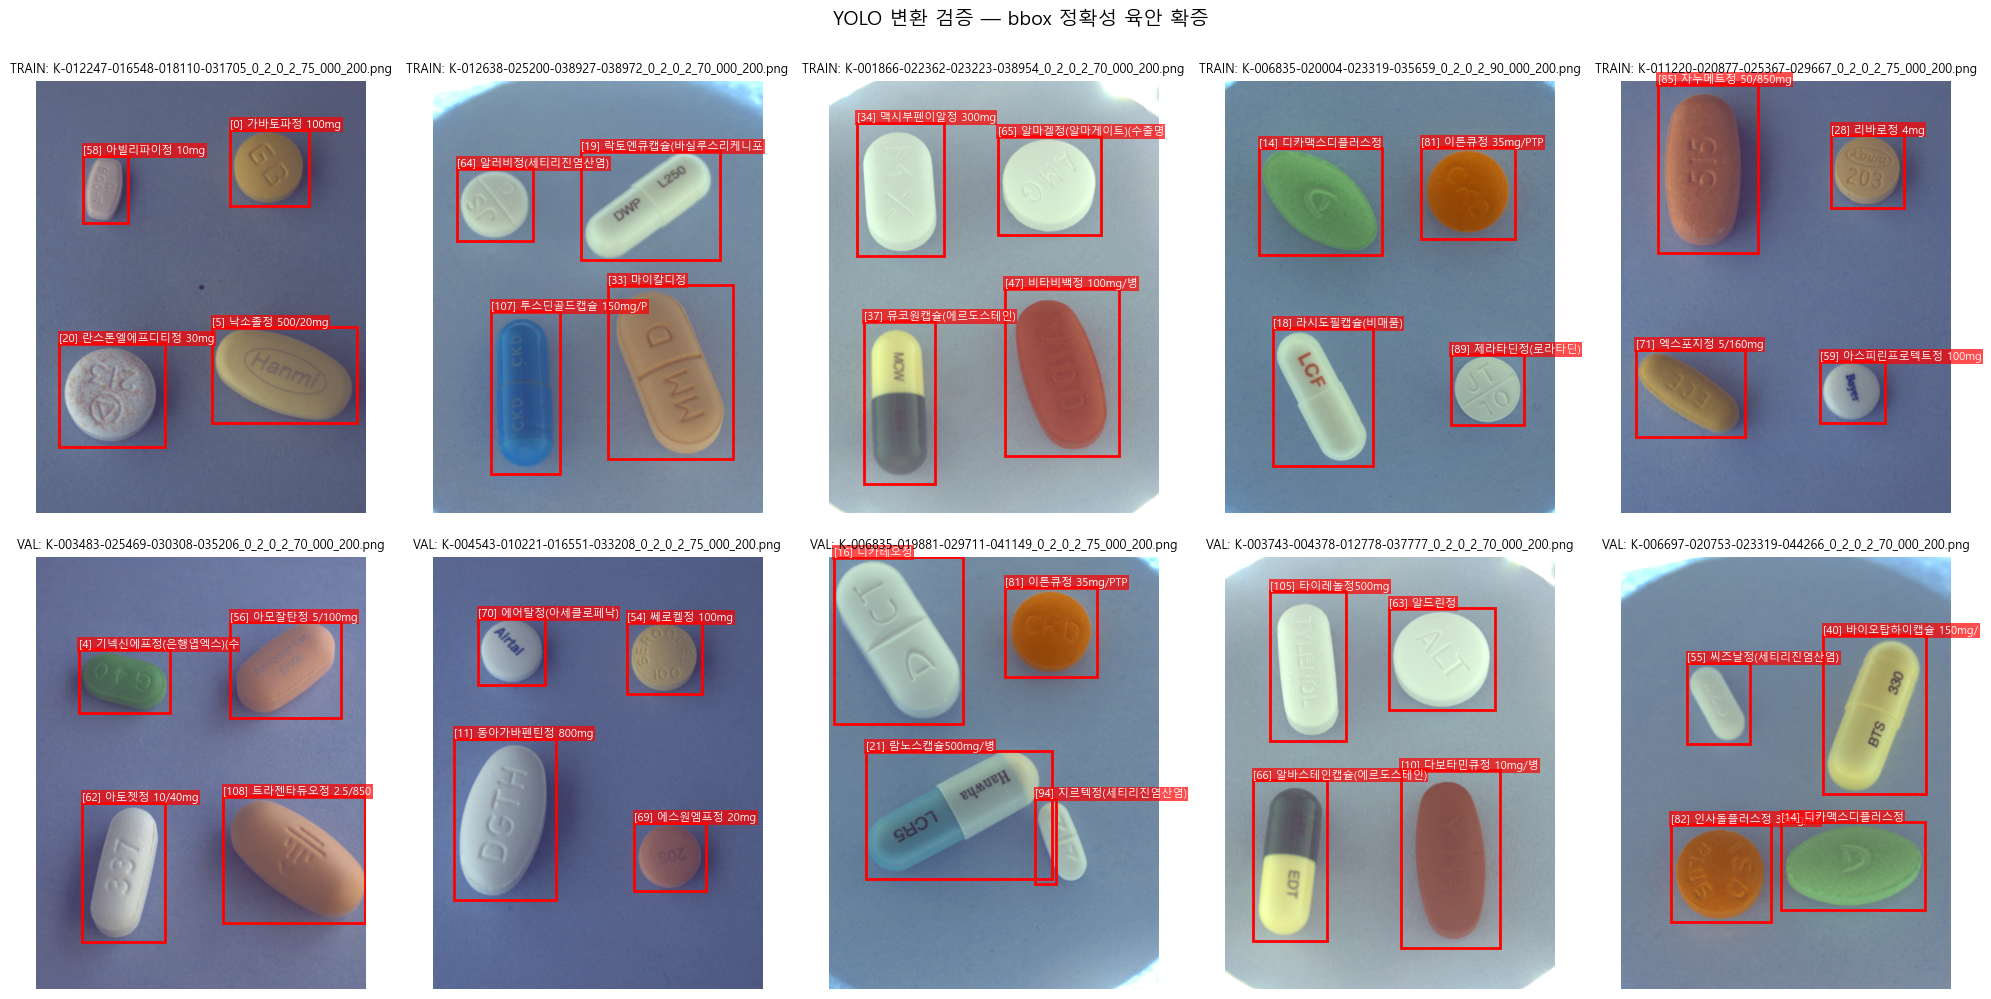


✅ 저장: D:\pill_detection\eda\figures\cell16_yolo_samples.png
   샘플: train 5장 + val 5장

🔍 육안 체크 포인트:
   1) bbox가 알약을 정확히 감싸는지
   2) 한 이미지에 여러 알약 있을 때 전부 박스됐는지
   3) 클래스명이 맞는지 (알약 외관 vs 이름)


In [44]:
# ============================================================
# Cell 16 — 샘플 시각화
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

FIGURES_DIR = EDA_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

def draw_yolo_sample(ax, img_path, lbl_path, title):
    """
    이미지 + YOLO 라벨 파싱해서 bbox 오버레이.
    """
    img = Image.open(img_path)
    W, H = img.size
    ax.imshow(img)
    
    # 라벨 파싱
    lines = lbl_path.read_text(encoding='utf-8').strip().split('\n')
    
    for line in lines:
        parts = line.split()
        cls  = int(parts[0])
        cx, cy, nw, nh = map(float, parts[1:])
        
        # YOLO normalized → 픽셀
        x = (cx - nw / 2) * W
        y = (cy - nh / 2) * H
        w = nw * W
        h = nh * H
        
        # bbox
        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        
        # 클래스명 라벨
        name = idx_to_name[cls]
        ax.text(x, y - 5, f"[{cls}] {name[:15]}",
                color='white', fontsize=8,
                bbox=dict(facecolor='red', alpha=0.7, pad=1, edgecolor='none'))
    
    ax.set_title(title, fontsize=9)
    ax.axis('off')

# 샘플 선택 (seed 고정)
rng = np.random.RandomState(42)

tr_imgs = sorted(YOLO_IMG_TR.glob("*.png"))
val_imgs = sorted(YOLO_IMG_VAL.glob("*.png"))

tr_sample  = rng.choice(tr_imgs, size=5, replace=False)
val_sample = rng.choice(val_imgs, size=5, replace=False)

# 시각화 (2행 5열)
fig, axes = plt.subplots(2, 5, figsize=(20, 10))

for i, img_path in enumerate(tr_sample):
    lbl_path = YOLO_LBL_TR / (img_path.stem + ".txt")
    draw_yolo_sample(axes[0, i], img_path, lbl_path, f"TRAIN: {img_path.name}")

for i, img_path in enumerate(val_sample):
    lbl_path = YOLO_LBL_VAL / (img_path.stem + ".txt")
    draw_yolo_sample(axes[1, i], img_path, lbl_path, f"VAL: {img_path.name}")

plt.suptitle("YOLO 변환 검증 — bbox 정확성 육안 확증", fontsize=14, y=1.00)
plt.tight_layout()

save_path = FIGURES_DIR / "cell16_yolo_samples.png"
plt.savefig(save_path, dpi=100, bbox_inches='tight')
plt.show()

print(f"\n✅ 저장: {save_path}")
print(f"   샘플: train 5장 + val 5장")
print(f"\n🔍 육안 체크 포인트:")
print(f"   1) bbox가 알약을 정확히 감싸는지")
print(f"   2) 한 이미지에 여러 알약 있을 때 전부 박스됐는지")
print(f"   3) 클래스명이 맞는지 (알약 외관 vs 이름)")

## Cell 17 — 클래스별 train/val 분포 통계

long-tail 구조 확인. 최희귀/최다 클래스 리스트.
cell17_class_distribution.png 저장.

클래스 long-tail (하위 10 / 상위 10)

[하위 10 — 희귀 클래스]
                         name  train  val  total
class_idx                                       
4          기넥신에프정(은행엽엑스)(수출용)     30   15     45
41                 베시케어정 10mg     59   21     80
111                 트루패스정 4mg     67   15     82
88               자트랄엑스엘정 10mg     72   12     84
106               토비애즈서방정 4mg     60   24     84
116                플리바스정 50mg     63   21     84
82           인사돌플러스정 35mg/PTP     63   27     90
73           엔트레스토필름코팅정 200mg     74   32    106
60            아질렉트정(라사길린메실산염)    116   20    136
2                   글리아타민연질캡슐    124   18    142

[상위 10 — 빈번 클래스]
                                    name  train  val  total
class_idx                                                  
28                              리바로정 4mg    488   87    575
62                          아토젯정 10/40mg    482   96    578
102                           크레스토정 20mg    480  110    590
115                           플라빅스정 75mg    46

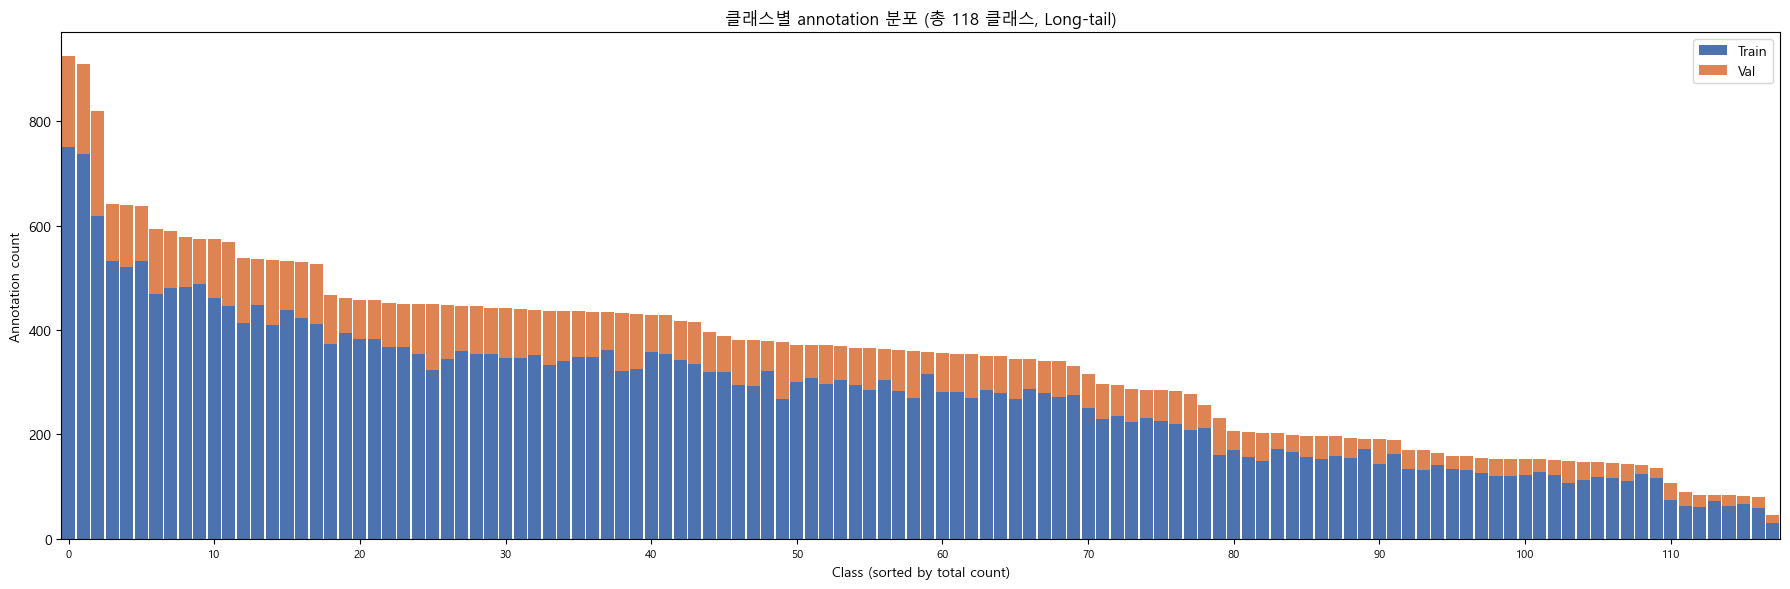


✅ 저장: D:\pill_detection\eda\figures\cell17_class_distribution.png


In [45]:
# ============================================================
# Cell 17 — 클래스별 통계 리포트
# ============================================================

# 클래스별 train/val 건수 집계
cls_stats = pd.DataFrame({
    'train': train_df['class_idx'].value_counts(),
    'val'  : val_df['class_idx'].value_counts(),
}).fillna(0).astype(int)
cls_stats['total']     = cls_stats['train'] + cls_stats['val']
cls_stats['val_ratio'] = (cls_stats['val'] / cls_stats['total']).round(3)
cls_stats['name']      = cls_stats.index.map(idx_to_name)
cls_stats = cls_stats.sort_values('total')

# (1) Long-tail 테이블 출력
print("=" * 60)
print("클래스 long-tail (하위 10 / 상위 10)")
print("=" * 60)
print("\n[하위 10 — 희귀 클래스]")
print(cls_stats[['name', 'train', 'val', 'total']].head(10).to_string())
print("\n[상위 10 — 빈번 클래스]")
print(cls_stats[['name', 'train', 'val', 'total']].tail(10).to_string())

# (2) 요약 통계
print()
print("=" * 60)
print("요약 통계")
print("=" * 60)
print(f"  클래스 수    : {len(cls_stats)}")
print(f"  총 annotation: {cls_stats['total'].sum():,}")
print(f"  min          : {cls_stats['total'].min()}")
print(f"  median       : {int(cls_stats['total'].median())}")
print(f"  max          : {cls_stats['total'].max()}")
print(f"  mean         : {cls_stats['total'].mean():.1f}")
print(f"  min/max 비율 : {cls_stats['total'].min() / cls_stats['total'].max():.3f}")

# (3) 시각화 (long-tail 막대그래프)
fig, ax = plt.subplots(figsize=(18, 6))

cls_sorted = cls_stats.sort_values('total', ascending=False)
x = range(len(cls_sorted))

ax.bar(x, cls_sorted['train'], color='#4C72B0', label='Train', width=0.9)
ax.bar(x, cls_sorted['val'], bottom=cls_sorted['train'],
       color='#DD8452', label='Val', width=0.9)

ax.set_xlabel('Class (sorted by total count)')
ax.set_ylabel('Annotation count')
ax.set_title(f'클래스별 annotation 분포 (총 118 클래스, Long-tail)')
ax.legend()
ax.set_xlim(-0.5, len(cls_sorted) - 0.5)

# X축 라벨은 10개마다만
tick_step = 10
ax.set_xticks(x[::tick_step])
ax.set_xticklabels([f"{i}" for i in x[::tick_step]], fontsize=8)

plt.tight_layout()

save_path = FIGURES_DIR / "cell17_class_distribution.png"
plt.savefig(save_path, dpi=100, bbox_inches='tight')
plt.show()

print(f"\n✅ 저장: {save_path}")

## Cell 18 — COCO JSON 생성 (Faster R-CNN용)

torchvision Faster R-CNN 학습용 COCO 포맷 annotation.
좌표는 COCO 표준 [x, y, w, h] 픽셀 그대로 유지.
train_coco.json, val_coco.json 저장.

In [46]:
# ============================================================
# Cell 18 — COCO JSON 생성 (Faster R-CNN용)
# ============================================================

import json
from datetime import datetime

def build_coco(df_split, split_name):
    """
    COCO 포맷 JSON 구성.
    images  : 고유 이미지 목록
    annotations: 모든 bbox
    categories: 118 클래스
    """
    # (1) images — 고유 이미지 단위
    unique_imgs = df_split[['image_file', 'image_path']].drop_duplicates('image_file')\
                                                        .reset_index(drop=True)
    
    # image_file → image_id 매핑 (0부터 순차)
    img_file_to_id = {row['image_file']: idx for idx, row in unique_imgs.iterrows()}
    
    images = []
    for idx, row in unique_imgs.iterrows():
        images.append({
            'id'       : idx,
            'file_name': row['image_file'],
            'width'    : 976,
            'height'   : 1280,
        })
    
    # (2) annotations — 모든 bbox
    annotations = []
    for ann_id, (_, row) in enumerate(df_split.iterrows()):
        x, y, w, h = float(row['bbox_x']), float(row['bbox_y']), \
                     float(row['bbox_w']), float(row['bbox_h'])
        annotations.append({
            'id'           : ann_id,
            'image_id'     : img_file_to_id[row['image_file']],
            'category_id'  : int(row['class_idx']),
            'bbox'         : [x, y, w, h],           # COCO: [x, y, w, h]
            'area'         : w * h,
            'iscrowd'      : 0,
        })
    
    # (3) categories — 118 클래스 (class_idx 0~117)
    categories = []
    for idx in range(118):
        categories.append({
            'id'  : idx,
            'name': idx_to_name[idx],
        })
    
    coco = {
        'info': {
            'description': f'Pill Detection {split_name} — {datetime.now().strftime("%Y-%m-%d")}',
            'version'    : '1.0',
        },
        'images'     : images,
        'annotations': annotations,
        'categories' : categories,
    }
    
    return coco, img_file_to_id

# (1) Train COCO 생성
print("=" * 60)
print("Train COCO JSON 생성")
print("=" * 60)
train_coco, tr_img_map = build_coco(train_df, "train")

with open(TRAIN_COCO, 'w', encoding='utf-8') as f:
    json.dump(train_coco, f, ensure_ascii=False, indent=None)

size_mb = TRAIN_COCO.stat().st_size / 1024 / 1024
print(f"  ✅ {TRAIN_COCO.name} ({size_mb:.2f} MB)")
print(f"     images      : {len(train_coco['images']):,}")
print(f"     annotations : {len(train_coco['annotations']):,}")
print(f"     categories  : {len(train_coco['categories'])}")

# (2) Val COCO 생성
print()
print("=" * 60)
print("Val COCO JSON 생성")
print("=" * 60)
val_coco, val_img_map = build_coco(val_df, "val")

with open(VAL_COCO, 'w', encoding='utf-8') as f:
    json.dump(val_coco, f, ensure_ascii=False, indent=None)

size_mb = VAL_COCO.stat().st_size / 1024 / 1024
print(f"  ✅ {VAL_COCO.name} ({size_mb:.2f} MB)")
print(f"     images      : {len(val_coco['images']):,}")
print(f"     annotations : {len(val_coco['annotations']):,}")
print(f"     categories  : {len(val_coco['categories'])}")

# (3) 불변 조건 검증
assert len(train_coco['images'])      == 8558
assert len(train_coco['annotations']) == 32601
assert len(val_coco['images'])        == 2139
assert len(val_coco['annotations'])   == 8130
assert len(train_coco['categories'])  == 118
assert len(val_coco['categories'])    == 118

# category_id 범위 확증
tr_cat_ids = {a['category_id'] for a in train_coco['annotations']}
val_cat_ids = {a['category_id'] for a in val_coco['annotations']}
assert tr_cat_ids == set(range(118))
assert val_cat_ids == set(range(118))

print()
print("=" * 60)
print("불변 조건 검증")
print("=" * 60)
print(f"  ✅ Train: 8,558 images / 32,601 annotations / 118 categories")
print(f"  ✅ Val  : 2,139 images / 8,130 annotations / 118 categories")
print(f"  ✅ category_id 전부 [0, 117]")

# (4) pycocotools 역로드 검증 (가능하면)
try:
    from pycocotools.coco import COCO
    print()
    print("=" * 60)
    print("pycocotools 역로드 검증")
    print("=" * 60)
    
    # pycocotools가 내부에서 cp949로 열어서 한글 깨짐 → dict 수동 주입
    with open(TRAIN_COCO, 'r', encoding='utf-8') as f:
        tr_dict = json.load(f)
    with open(VAL_COCO, 'r', encoding='utf-8') as f:
        val_dict = json.load(f)
    
    coco_tr = COCO()
    coco_tr.dataset = tr_dict
    coco_tr.createIndex()
    
    coco_val = COCO()
    coco_val.dataset = val_dict
    coco_val.createIndex()
    
    print(f"  ✅ Train COCO 로드: {len(coco_tr.imgs)} imgs / "
          f"{len(coco_tr.anns)} anns / {len(coco_tr.cats)} cats")
    print(f"  ✅ Val   COCO 로드: {len(coco_val.imgs)} imgs / "
          f"{len(coco_val.anns)} anns / {len(coco_val.cats)} cats")
except ImportError:
    print()
    print("⚠️  pycocotools 미설치 — 04에서 `pip install pycocotools` 필요")

Train COCO JSON 생성
  ✅ train_coco.json (4.67 MB)
     images      : 8,558
     annotations : 32,601
     categories  : 118

Val COCO JSON 생성
  ✅ val_coco.json (1.16 MB)
     images      : 2,139
     annotations : 8,130
     categories  : 118

불변 조건 검증
  ✅ Train: 8,558 images / 32,601 annotations / 118 categories
  ✅ Val  : 2,139 images / 8,130 annotations / 118 categories
  ✅ category_id 전부 [0, 117]

pycocotools 역로드 검증
creating index...
index created!
creating index...
index created!
  ✅ Train COCO 로드: 8558 imgs / 32601 anns / 118 cats
  ✅ Val   COCO 로드: 2139 imgs / 8130 anns / 118 cats


## Cell 19 — Closure

train/val.csv, split_info.json 저장. 산출물 요약 + 04 진입점.

In [47]:
# ============================================================
# Cell 19 — Closure
# ============================================================

import json
from datetime import datetime

# CSV 저장
cols_to_save = [
    'source', 'combo', 'image_file', 'image_path',
    'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h',
    'class_idx', 'img_dl_name', 'img_dl_mapping_code', 'img_drug_N',
]

train_df[cols_to_save].to_csv(TRAIN_CSV, index=False, encoding='utf-8-sig')
val_df[cols_to_save].to_csv(VAL_CSV, index=False, encoding='utf-8-sig')

print("=" * 60)
print("DataFrame 저장")
print("=" * 60)
print(f"  {TRAIN_CSV.name} : {TRAIN_CSV.stat().st_size / 1024 / 1024:.2f} MB "
      f"({len(train_df):,} rows)")
print(f"  {VAL_CSV.name}   : {VAL_CSV.stat().st_size / 1024 / 1024:.2f} MB "
      f"({len(val_df):,} rows)")

# split_info.json
split_info = {
    'created_at' : datetime.now().isoformat(timespec='seconds'),
    'seed'       : SEED,
    'val_ratio'  : 0.2,
    'strategy'   : 'GroupShuffleSplit by combo',
    'counts': {
        'total_annotations' : len(df_clean),
        'train_annotations' : len(train_df),
        'val_annotations'   : len(val_df),
        'train_images'      : int(train_df['image_file'].nunique()),
        'val_images'        : int(val_df['image_file'].nunique()),
        'train_combos'      : int(train_df['combo'].nunique()),
        'val_combos'        : int(val_df['combo'].nunique()),
        'classes'           : 118,
    },
    'image_resolution': {'width': 976, 'height': 1280},
    'excluded_count' : 494,
    'exclusion_breakdown': {
        'parse_error'    : 324,
        'issue_A'        : 58,
        'issue_B_extreme': 40,
        'issue_L'        : 1,
        'issue_C_dedup'  : 71,
    },
    'class_stats': {
        'min'    : int(cls_stats['total'].min()),
        'max'    : int(cls_stats['total'].max()),
        'median' : int(cls_stats['total'].median()),
        'min_val': int(cls_stats['val'].min()),
    },
}

with open(SPLIT_INFO_JSON, 'w', encoding='utf-8') as f:
    json.dump(split_info, f, indent=2, ensure_ascii=False)

print(f"  {SPLIT_INFO_JSON.name} : {SPLIT_INFO_JSON.stat().st_size} bytes")

# 산출물 요약
print()
print("=" * 60)
print("03_preprocessing 산출물")
print("=" * 60)

outputs = [
    ('YOLO images/train', YOLO_IMG_TR, '*.png'),
    ('YOLO images/val',   YOLO_IMG_VAL, '*.png'),
    ('YOLO labels/train', YOLO_LBL_TR, '*.txt'),
    ('YOLO labels/val',   YOLO_LBL_VAL, '*.txt'),
    ('data.yaml',         DATA_YAML, None),
    ('train_coco.json',   TRAIN_COCO, None),
    ('val_coco.json',     VAL_COCO, None),
    ('class_mapping.pkl', CLASS_MAP_PKL, None),
    ('train.csv',         TRAIN_CSV, None),
    ('val.csv',           VAL_CSV, None),
    ('split_info.json',   SPLIT_INFO_JSON, None),
]

for name, path, pattern in outputs:
    if pattern is None:
        if path.exists():
            size_mb = path.stat().st_size / 1024 / 1024
            print(f"  ✅ {name:22s} {path.name} ({size_mb:.2f} MB)")
    else:
        n = len(list(path.glob(pattern)))
        print(f"  ✅ {name:22s} {n:,} files")

# 04 진입점
print()
print("=" * 60)
print("04_baseline 진입점")
print("=" * 60)
print(f"[YOLOv8]")
print(f"  data_yaml = {DATA_YAML}")
print()
print(f"[Faster R-CNN (torchvision)]")
print(f"  train_coco = {TRAIN_COCO}")
print(f"  val_coco   = {VAL_COCO}")
print(f"  images_dir = {YOLO_ROOT / 'images'}")
print()
print(f"[공통]")
print(f"  nc         = 118")
print(f"  해상도     : 976×1280 (입력 권장 1024+)")
print(f"  클래스 매핑: {CLASS_MAP_PKL}")
print()
print("🎉 03_preprocessing.ipynb 완결")

DataFrame 저장
  train.csv : 8.88 MB (32,601 rows)
  val.csv   : 2.21 MB (8,130 rows)
  split_info.json : 709 bytes

03_preprocessing 산출물
  ✅ YOLO images/train      8,558 files
  ✅ YOLO images/val        2,139 files
  ✅ YOLO labels/train      8,558 files
  ✅ YOLO labels/val        2,139 files
  ✅ data.yaml              data.yaml (0.00 MB)
  ✅ train_coco.json        train_coco.json (4.67 MB)
  ✅ val_coco.json          val_coco.json (1.16 MB)
  ✅ class_mapping.pkl      class_mapping.pkl (0.01 MB)
  ✅ train.csv              train.csv (8.88 MB)
  ✅ val.csv                val.csv (2.21 MB)
  ✅ split_info.json        split_info.json (0.00 MB)

04_baseline 진입점
[YOLOv8]
  data_yaml = D:\pill_detection\data\yolo\data.yaml

[Faster R-CNN (torchvision)]
  train_coco = D:\pill_detection\data\coco\train_coco.json
  val_coco   = D:\pill_detection\data\coco\val_coco.json
  images_dir = D:\pill_detection\data\yolo\images

[공통]
  nc         = 118
  해상도     : 976×1280 (입력 권장 1024+)
  클래스 매핑: D:\pill_detec

## Cell 20 — 누락 annotation 최종 검증

combo 폴더명이 명시한 알약 개수 vs 실제 annotation 개수 대조.
AI Hub 조합 구조상 누락 가능성 낮지만 본학습 전 안전장치.

In [51]:
# 올바른 방법: combo를 '-'로 split해서 K-code 개수 추출
def count_kcodes(combo_str):
    # 'K-001900-016548-019607-029451' → ['K', '001900', '016548', ...]
    return len(combo_str.split('-')) - 1

expected = df_clean.groupby('image_file')['combo'].first().apply(count_kcodes)
actual   = df_clean.groupby('image_file').size()

check = pd.DataFrame({'expected': expected, 'actual': actual})
check['diff'] = check['expected'] - check['actual']

missing  = check[check['diff'] > 0]  # expected > actual → 누락
overflow = check[check['diff'] < 0]  # expected < actual → 과다 (이슈 N 잔여)
match    = check[check['diff'] == 0]

print("=" * 60)
print("누락/과다 최종 검증 (올바른 로직)")
print("=" * 60)
print(f"  총 이미지      : {len(check):,}")
print(f"  예상==실제 일치 : {len(match):,}")
print(f"  🔴 누락(예상>실제) : {len(missing):,}")
print(f"  🔴 과다(예상<실제) : {len(overflow):,}")

if len(missing) > 0:
    print()
    print("[누락 샘플 10건]")
    print(missing.head(10))

if len(overflow) > 0:
    print()
    print("[과다 샘플 10건]")
    print(overflow.head(10))

누락/과다 최종 검증 (올바른 로직)
  총 이미지      : 10,697
  예상==실제 일치 : 10,357
  🔴 누락(예상>실제) : 324
  🔴 과다(예상<실제) : 16

[누락 샘플 10건]
                                                    expected  actual  diff
image_file                                                                
K-000250-000573-002483-012778_0_2_0_2_70_000_20...         4       3     1
K-000250-000573-005002-012778_0_2_0_2_75_000_20...         4       3     1
K-000250-000573-005002-012778_0_2_0_2_90_000_20...         4       3     1
K-000250-000573-022627-037777_0_2_0_2_90_000_20...         4       3     1
K-000250-000573-023223-037777_0_2_0_2_75_000_20...         4       2     2
K-000250-002483-005886-006192_0_2_0_2_90_000_20...         4       3     1
K-000250-002483-005886-023223_0_2_0_2_70_000_20...         4       3     1
K-000250-002483-006192-013395_0_2_0_2_90_000_20...         4       3     1
K-000250-002483-006192-022362_0_2_0_2_70_000_20...         4       3     1
K-000250-002483-012081-012778_0_2_0_2_70_000_20...         

In [52]:
# ① 누락 324건 원인 검증: parse_error 때문인지
missing_imgs = set(missing.index)

# 원본(제외 전) 기준으로 누락 의심 이미지에서 parse_error 상태 확인
original = df_report[df_report['image_file'].isin(missing_imgs)]
pe_in_missing = original[original['parse_error'].notna()]

print("=" * 60)
print("누락 324건 원인 검증")
print("=" * 60)
print(f"누락 의심 이미지: {len(missing_imgs)}장")
print(f"해당 이미지에 있는 원본 레코드: {len(original)}")
print(f"  └ parse_error 있음: {len(pe_in_missing)}건")
print(f"  └ parse_error 없음: {len(original) - len(pe_in_missing)}건")
print()
print("parse_error 사유별:")
print(pe_in_missing['parse_error'].value_counts())

# ② 과다 16건 원인 검증: 실제로 한 이미지에 5~6개 라벨 있는지
print()
print("=" * 60)
print("과다 16건 원인 검증")
print("=" * 60)
overflow_imgs = set(overflow.index)
over_original = df_report[df_report['image_file'].isin(overflow_imgs)]
print(f"과다 이미지: {len(overflow_imgs)}장")
print(f"해당 이미지 원본 레코드 수: {len(over_original)}")
print(f"제외된 레코드: {over_original['exclude_from_train'].sum()}")

# 과다 이미지 한 장 자세히
sample_img = list(overflow_imgs)[0]
print()
print(f"샘플 이미지 '{sample_img}'")
sample_records = df_clean[df_clean['image_file'] == sample_img][
    ['source', 'img_dl_name', 'img_dl_mapping_code', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h']
]
print(sample_records.to_string())

누락 324건 원인 검증
누락 의심 이미지: 324장
해당 이미지에 있는 원본 레코드: 1220
  └ parse_error 있음: 130건
  └ parse_error 없음: 1090건

parse_error 사유별:
parse_error
bbox_format_error    130
Name: count, dtype: int64

과다 16건 원인 검증
과다 이미지: 16장
해당 이미지 원본 레코드 수: 85
제외된 레코드: 0

샘플 이미지 'K-001900-003544-016551-029451_0_2_0_2_90_000_200.png'
             source        img_dl_name img_dl_mapping_code  bbox_x  bbox_y  bbox_w  bbox_h
6308  aihub_ts1_tl1         보령부스파정 5mg            K-001900   148.0   241.0   182.0   181.0
6309  aihub_ts1_tl1         보령부스파정 5mg            K-001900   169.0   248.0   183.0   179.0
6312  aihub_ts1_tl1  무코스타정(레바미피드)(비매품)            K-003544   659.0   201.0   211.0   202.0
6315  aihub_ts1_tl1      동아가바펜틴정 800mg            K-016551    51.0   722.0   297.0   478.0
6317  aihub_ts1_tl1               레일라정            K-029451   468.0   787.0   405.0   267.0
6318  aihub_ts1_tl1               레일라정            K-029451   498.0   820.0   398.0   269.0


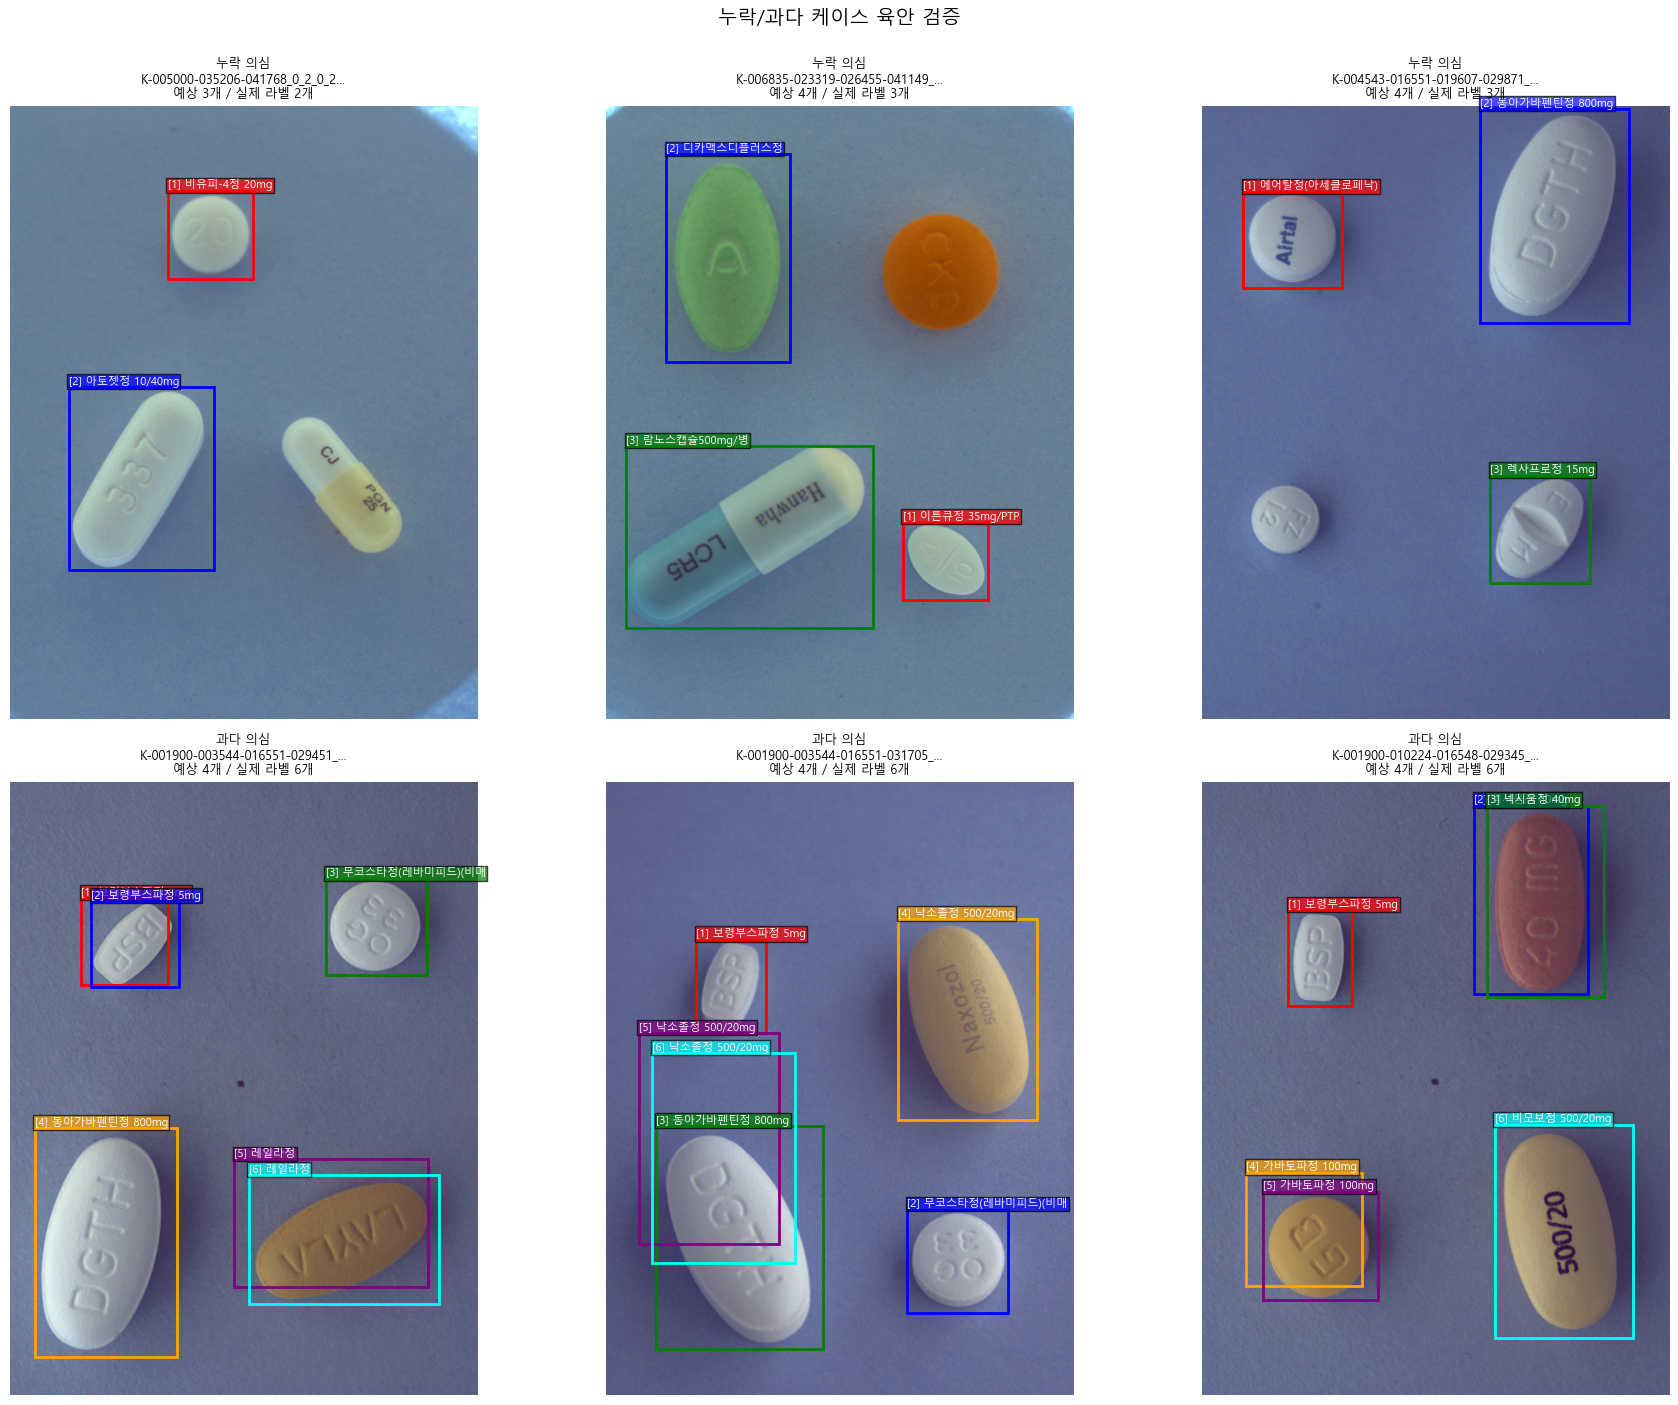

In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def show_image_with_bbox(ax, df_rows, img_path, title):
    """이미지에 bbox 다 그려서 표시"""
    img = Image.open(img_path)
    ax.imshow(img)
    
    colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']
    for i, (_, row) in enumerate(df_rows.iterrows()):
        x, y = row['bbox_x'], row['bbox_y']
        w, h = row['bbox_w'], row['bbox_h']
        color = colors[i % len(colors)]
        
        rect = patches.Rectangle((x, y), w, h, linewidth=2, 
                                  edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        ax.text(x, y - 5, f"[{i+1}] {row['img_dl_name'][:15]}",
                color='white', fontsize=8,
                bbox=dict(facecolor=color, alpha=0.7, pad=1))
    
    ax.set_title(title, fontsize=9)
    ax.axis('off')

# 누락 샘플 3장 + 과다 샘플 3장
missing_samples = list(missing_imgs)[:3]
overflow_samples = list(overflow_imgs)[:3]

fig, axes = plt.subplots(2, 3, figsize=(18, 14))

# 누락 케이스 (expected=4, actual=3 등)
for i, img_file in enumerate(missing_samples):
    rows = df_clean[df_clean['image_file'] == img_file]
    img_path = rows['image_path'].iloc[0]
    n_exp = rows['combo'].iloc[0].count('-')  # K-code 개수
    n_act = len(rows)
    show_image_with_bbox(
        axes[0, i], rows, img_path,
        f"누락 의심\n{img_file[:30]}...\n예상 {n_exp}개 / 실제 라벨 {n_act}개"
    )

# 과다 케이스 (expected=4, actual=5~6)
for i, img_file in enumerate(overflow_samples):
    rows = df_clean[df_clean['image_file'] == img_file]
    img_path = rows['image_path'].iloc[0]
    n_exp = rows['combo'].iloc[0].count('-')
    n_act = len(rows)
    show_image_with_bbox(
        axes[1, i], rows, img_path,
        f"과다 의심\n{img_file[:30]}...\n예상 {n_exp}개 / 실제 라벨 {n_act}개"
    )

plt.suptitle("누락/과다 케이스 육안 검증", fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

In [54]:
from itertools import combinations

def compute_iou(b1, b2):
    """COCO [x,y,w,h] 기준 IoU"""
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    
    xi1 = max(x1, x2)
    yi1 = max(y1, y2)
    xi2 = min(x1 + w1, x2 + w2)
    yi2 = min(y1 + h1, y2 + h2)
    
    inter = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    union = w1 * h1 + w2 * h2 - inter
    return inter / union if union > 0 else 0

# df_clean에서 이미지별 pair 전수 IoU 계산
pair_results = []

for img_file, group in tqdm(df_clean.groupby('image_file'), desc="IoU 검증"):
    rows = group.reset_index(drop=True)
    for i, j in combinations(range(len(rows)), 2):
        r1 = rows.iloc[i]
        r2 = rows.iloc[j]
        
        iou = compute_iou(
            (r1['bbox_x'], r1['bbox_y'], r1['bbox_w'], r1['bbox_h']),
            (r2['bbox_x'], r2['bbox_y'], r2['bbox_w'], r2['bbox_h'])
        )
        
        if iou > 0.3:  # 의심 pair만 기록
            pair_results.append({
                'image_file': img_file,
                'class_1'   : r1['img_dl_name'],
                'class_2'   : r2['img_dl_name'],
                'same_class': r1['img_dl_name'] == r2['img_dl_name'],
                'iou'       : iou,
            })

pair_df = pd.DataFrame(pair_results)

print("=" * 60)
print("이미지 내 bbox pair IoU > 0.3 전수 조사")
print("=" * 60)
print(f"의심 pair 총: {len(pair_df)}건")
print()
print("IoU 구간별 + 같은 클래스 여부:")
pair_df['iou_bin'] = pd.cut(pair_df['iou'], 
                              bins=[0.3, 0.5, 0.7, 0.9, 1.01],
                              labels=['0.3-0.5', '0.5-0.7', '0.7-0.9', '0.9-1.0'])
print(pd.crosstab(pair_df['iou_bin'], pair_df['same_class'], margins=True))

# 의심 케이스: IoU > 0.5 AND 같은 클래스
suspect = pair_df[(pair_df['iou'] > 0.5) & (pair_df['same_class'])]
print()
print(f"🚨 같은 클래스 + IoU > 0.5: {len(suspect)}건")
print(f"   해당 이미지 수: {suspect['image_file'].nunique()}")

# 서로 다른 클래스인데 IoU 높은 케이스 (dedup하면 안 되는 것)
diff_class = pair_df[(pair_df['iou'] > 0.5) & (~pair_df['same_class'])]
print()
print(f"⚠️  다른 클래스 + IoU > 0.5 (dedup 금지 대상): {len(diff_class)}건")
if len(diff_class) > 0:
    print(diff_class.head(5).to_string())

IoU 검증: 100%|██████████| 10697/10697 [00:10<00:00, 1020.31it/s]

이미지 내 bbox pair IoU > 0.3 전수 조사
의심 pair 총: 58건

IoU 구간별 + 같은 클래스 여부:
same_class  False  True  All
iou_bin                     
0.3-0.5        25     0   25
0.5-0.7        11    11   22
0.7-0.9         2     7    9
0.9-1.0         2     0    2
All            40    18   58

🚨 같은 클래스 + IoU > 0.5: 18건
   해당 이미지 수: 16

⚠️  다른 클래스 + IoU > 0.5 (dedup 금지 대상): 15건
                                             image_file                    class_1          class_2  same_class       iou  iou_bin
1  K-000250-004378-012778-038954_0_2_0_2_70_000_200.png              다보타민큐정 10mg/병    뮤코원캡슐(에르도스테인)       False  0.523878  0.5-0.7
2  K-000250-005002-005886-023223_0_2_0_2_75_000_200.png         엘도스캡슐(에르도스테인)(수출용)    비타비백정 100mg/병       False  0.715333  0.7-0.9
3  K-000573-002483-023223-025438_0_2_0_2_75_000_200.png                뮤테란캡슐 100mg  큐시드정 31.5mg/PTP       False  0.505141  0.5-0.7
4  K-000573-003743-019552-044834_0_2_0_2_70_000_200.png                       알드린정     트루비타정 60mg/병       False  0.518

---

# 📋 preprocessing 총정리

## 데이터
- 학습 가능 **40,731건** (41,225에서 494 제외)
- 이미지 **10,697장** / 클래스 **118종** / combo **3,604개**
- 해상도 976×1280 단일, bbox 위반 0건

## Split (Combo Group, seed=42)
- Train 32,601 / Val 8,130 (val 19.96%)
- 이미지·combo overlap 0, 클래스 118/118
- val 최소 12건 (자트랄엑스엘정 10mg)

## 변환
- **YOLO**: normalized (cx, cy, w, h), 8,558 + 2,139 txt
- **COCO**: 픽셀 [x,y,w,h], pycocotools 검증 통과
- 이미지는 복사 방식 (18 GB), 심볼릭 링크 X

## 04 진입점
- YOLOv8 → `data/yolo/data.yaml`
- Faster R-CNN → `data/coco/{train,val}_coco.json`
- 이미지 공통 → `data/yolo/images/{train,val}/`

## 주요 인사이트
- `img_dl_name` 118종이 유일한 신뢰 가능 클래스 레이블. `dl_idx`는 source별 분리되어 위험
- 클래스 min/max 비율 0.049 → moderate imbalance. 표준 loss로 충분
- 최희귀 클래스 val 12건 확보 → mAP 통계 신뢰성 OK
- 입력 해상도 1024+ 필수 (640에서 각인 소실)
- 증강 금지: 블러/극단 downsample/흑백화/넓은 Cutout